# Binary + Heatmap Prediction Check

Each config is plotted on a separate row. The first row is the binary model, the second row is the centre-heatmap model. The rightmost column is reserved for calculated ROIs.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

PROJECT_ROOT = os.path.abspath(".")
if not os.path.exists(os.path.join(PROJECT_ROOT, "config", "binary_model_v5_synaptic.yml")):
    PROJECT_ROOT = os.path.abspath("MONAI-test")
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from monai.data import Dataset
from monai.transforms import Compose, EnsureChannelFirstd, EnsureTyped, ScaleIntensityd, DeleteItemsd
from monai.visualize.utils import blend_images

from src import data, transforms, inference
from src.config import load_yaml_config
from src.model import build_binary_model

CONFIG_PATHS = [
    os.path.join(PROJECT_ROOT, "config", "binary_model_v5_synaptic.yml"),
    os.path.join(PROJECT_ROOT, "config", "heatmap_model_v5_synaptic.yml"),
]

def resolve_project_path(path):
    if os.path.isabs(path):
        return path
    return os.path.join(PROJECT_ROOT, path)

configured_device = load_yaml_config(CONFIG_PATHS[0])["training"].get("device", "auto")
if configured_device == "auto":
    if torch.cuda.is_available():
        device = torch.device("cuda")
    elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        device = torch.device("mps")
    else:
        device = torch.device("cpu")
else:
    device = torch.device(configured_device)

print("Using device:", device)


Using device: mps


In [2]:
def infer_run_kind(config_path, config):
    name = os.path.basename(config_path).lower()
    label_suffix = str(config["data"].get("label_suffix", "")).lower()
    if "heatmap" in name or "heatmap" in label_suffix:
        return "heatmap"
    return "binary"


def build_transform_pair(run):
    config = run["config"]
    data_config = config["data"]
    augmentation_config = config["augmentation"]
    transform_fn = (
        transforms.get_transforms_heatmap_classification
        if run["kind"] == "heatmap"
        else transforms.get_transforms_binary_classification
    )

    return transform_fn(
        num_samples=data_config["num_samples"],
        spatial_size=tuple(data_config["patch_size"]),
        pos=data_config["pos"],
        neg=data_config["neg"],
        filter_by_annotation=data_config.get("require_annotations", True),
        annotation_indices=data_config["annotation_indices"],
        flip_vertical=augmentation_config["flip_vertical"],
        flip_vertical_prob=augmentation_config["flip_vertical_prob"],
        flip_horizontal=augmentation_config["flip_horizontal"],
        flip_horizontal_prob=augmentation_config["flip_horizontal_prob"],
        rotate90=augmentation_config["rotate90"],
        rotate90_prob=augmentation_config["rotate90_prob"],
        rotate90_max_k=augmentation_config["rotate90_max_k"],
        intensity_scale=augmentation_config["intensity_scale"],
        intensity_scale_prob=augmentation_config["intensity_scale_prob"],
        intensity_scale_factors=augmentation_config["intensity_scale_factors"],
        intensity_shift=augmentation_config["intensity_shift"],
        intensity_shift_prob=augmentation_config["intensity_shift_prob"],
        intensity_shift_offsets=augmentation_config["intensity_shift_offsets"],
    )


def build_original_label_transform(data_config):
    if data_config.get("require_annotations", True):
        transform_list = [transforms.LoadTiffd(keys=["image", "label", "annotation"])]
        transform_list.extend([
            transforms.FilterByAnnotationd(
                mask_key="label",
                annotation_key="annotation",
                annotation_indices=data_config["annotation_indices"],
            ),
            DeleteItemsd(keys=["annotation"]),
        ])
    else:
        transform_list = [transforms.LoadTiffd(keys=["image", "label"])]

    transform_list.extend([
        EnsureChannelFirstd(keys=["image", "label"], channel_dim="no_channel"),
        ScaleIntensityd(keys=["image"]),
        EnsureTyped(keys=["image", "label"], dtype=torch.float32),
    ])
    return Compose(transform_list)


def make_overlay(image_chw, label_chw, alpha=0.35):
    image_chw = image_chw.detach().cpu()
    label_chw = label_chw.detach().cpu()
    blended = blend_images(
        image=image_chw,
        label=label_chw,
        alpha=alpha,
        cmap="hsv",
        rescale_arrays=True,
        transparent_background=True,
    )
    if torch.is_tensor(blended):
        blended = blended.detach().cpu().numpy()
    return np.moveaxis(np.asarray(blended), 0, -1)


def find_matching_index(records, image_path):
    for idx, record in enumerate(records):
        if record.get("image_path", record.get("image")) == image_path:
            return idx
    return 0


def dice_score(target, prediction, eps=1e-8):
    target = np.asarray(target) > 0
    prediction = np.asarray(prediction) > 0
    intersection = np.logical_and(target, prediction).sum()
    return (2.0 * intersection + eps) / (target.sum() + prediction.sum() + eps)


def compact_instance_labels(labels):
    labels = np.asarray(labels).astype(np.int64)
    output = np.zeros(labels.shape, dtype=np.int32)
    nonzero = labels > 0
    values = np.unique(labels[nonzero])
    if values.size:
        output[nonzero] = np.searchsorted(values, labels[nonzero]) + 1
    return output


def panoptic_quality_components(gt_instances, pred_instances, iou_threshold=0.5):
    gt = compact_instance_labels(gt_instances)
    pred = compact_instance_labels(pred_instances)
    gt_count = int(gt.max())
    pred_count = int(pred.max())

    if gt_count == 0 and pred_count == 0:
        return {"rq": 1.0, "sq": 1.0, "tp": 0, "fp": 0, "fn": 0}
    if gt_count == 0:
        return {"rq": 0.0, "sq": 0.0, "tp": 0, "fp": pred_count, "fn": 0}
    if pred_count == 0:
        return {"rq": 0.0, "sq": 0.0, "tp": 0, "fp": 0, "fn": gt_count}

    pair_ids = gt.ravel() * (pred_count + 1) + pred.ravel()
    intersections = np.bincount(
        pair_ids,
        minlength=(gt_count + 1) * (pred_count + 1),
    ).reshape(gt_count + 1, pred_count + 1)

    gt_areas = np.bincount(gt.ravel(), minlength=gt_count + 1)
    pred_areas = np.bincount(pred.ravel(), minlength=pred_count + 1)
    intersections = intersections[1:, 1:]
    unions = gt_areas[1:, None] + pred_areas[None, 1:] - intersections
    ious = np.divide(
        intersections,
        unions,
        out=np.zeros(intersections.shape, dtype=np.float32),
        where=unions > 0,
    )

    gt_matches, pred_matches = np.where(ious > iou_threshold)
    matched_ious = ious[gt_matches, pred_matches]
    tp = len(matched_ious)
    fp = pred_count - tp
    fn = gt_count - tp
    rq_denominator = tp + 0.5 * fp + 0.5 * fn
    rq = tp / rq_denominator if rq_denominator else 0.0
    sq = float(matched_ious.mean()) if tp else 0.0
    return {"rq": float(rq), "sq": sq, "tp": tp, "fp": fp, "fn": fn}


In [3]:
model_runs = []

for config_path in CONFIG_PATHS:
    config = load_yaml_config(config_path)
    data_config = config["data"]
    data_dir = resolve_project_path(data_config["data_dir"])
    excel_folder = resolve_project_path(data_config["excel_folder"])
    split_file = resolve_project_path(data_config["split_file"])

    if data_config.get("load_local_dataset", False):
        dfdata = pd.read_csv(os.path.join(data_dir, "dfdata.csv"))
    else:
        alldata = data.load_all_excels(
            folder=excel_folder,
            drive=data_config["drive"],
            exclusions=None if data_config.get("exclusions", None) == "None" else data_config.get("exclusions", None),
            inclusions=None if data_config.get("inclusions", None) == "None" else data_config.get("inclusions", None),
        )
        dfdata = data.generate_dataset(
            alldata,
            copy_type=data_config["copy_type"],
            overwrite=data_config["overwrite"],
            local_data_folder=data_dir,
            require_annotations=data_config.get("require_annotations", True),
            annotation_labels=data_config.get("annotation_indices", [1, 2, 5]),
            maskfilename=data_config.get("maskfilename", "Masks.tif"),
            generate_heatmaps=data_config.get("generate_heatmaps", False),
            heatmap_sigma=data_config.get("heatmap_sigma", 2),
            overwrite_heatmaps=data_config.get("overwrite_heatmaps", False),
        )

    train_data, val_data = data.train_test_split(
        dfdata,
        column=data_config["column"],
        test_size=data_config["test_size"],
        random_state=data_config["random_state"],
        split_json_path=split_file,
        save_split_json=data_config["save_split_json"],
        data_dir=data_dir,
        require_annotations=data_config.get("require_annotations", True),
        label_suffix=data_config.get("label_suffix", "_Masks") + ".tif",
    )

    run = {
        "name": os.path.splitext(os.path.basename(config_path))[0],
        "config_path": config_path,
        "config": config,
        "kind": infer_run_kind(config_path, config),
        "train_data": train_data,
        "val_data": val_data,
    }

    train_transforms, val_transforms = build_transform_pair(run)
    run["train_transforms"] = train_transforms
    run["val_transforms"] = val_transforms
    run["train_ds"], run["train_loader"], run["val_ds"], run["val_loader"] = data.create_datasets_and_loaders(
        train_data,
        val_data,
        train_transforms,
        val_transforms,
        batch_size=config["training"]["batch_size"],
        val_batch_size=config["training"]["val_batch_size"],
        num_workers=config["training"]["num_workers"],
        shuffle_train=config["training"]["shuffle_train"],
        shuffle_val=config["training"]["shuffle_val"],
    )

    model_runs.append(run)
    print(f"Prepared {run['name']} ({run['kind']}): train={len(train_data)}, val={len(val_data)}")

binary_run = next(run for run in model_runs if run["kind"] == "binary")
binary_run["original_label_ds"] = Dataset(
    data=binary_run["val_data"],
    transform=build_original_label_transform(binary_run["config"]["data"]),
)


100%|██████████| 297/297 [00:00<00:00, 23169.93it/s]

Avg file does not exist locally: /Users/federico/Documents/git-repos/cochlea-synapses-binary-segmentation-unet2d/data_sgn/2023_03_31_NeuroD-GCaMP6f_P4_in vivo_1_Avg.tif
Avg file does not exist locally: /Users/federico/Documents/git-repos/cochlea-synapses-binary-segmentation-unet2d/data_sgn/2023_04_04_NeuroD-GCaMP6f_P8_in vivo_1_Avg.tif
Avg file does not exist locally: /Users/federico/Documents/git-repos/cochlea-synapses-binary-segmentation-unet2d/data_sgn/2023_06_09_NeuroD-GCaMP6f_P8_in vivo_1_Avg.tif
Avg file does not exist locally: /Users/federico/Documents/git-repos/cochlea-synapses-binary-segmentation-unet2d/data_sgn/2025_04_28_NeuroD-GCaMP6f_P7_in vivo_injectable anaesthetic_3_Avg.tif
Avg file does not exist locally: /Users/federico/Documents/git-repos/cochlea-synapses-binary-segmentation-unet2d/data_sgn/2025_04_28_NeuroD-GCaMP6f_P7_in vivo_injectable anaesthetic_3_001_Avg.tif
Avg file does not exist locally: /Users/federico/Documents/git-repos/cochlea-synapses-binary-segmentation

Prepared binary_model_v5_synaptic (binary): train=196, val=49


100%|██████████| 297/297 [00:00<00:00, 27123.66it/s]

Avg file does not exist locally: /Users/federico/Documents/git-repos/cochlea-synapses-binary-segmentation-unet2d/data_sgn/2023_03_31_NeuroD-GCaMP6f_P4_in vivo_1_Avg.tif
Avg file does not exist locally: /Users/federico/Documents/git-repos/cochlea-synapses-binary-segmentation-unet2d/data_sgn/2023_04_04_NeuroD-GCaMP6f_P8_in vivo_1_Avg.tif
Avg file does not exist locally: /Users/federico/Documents/git-repos/cochlea-synapses-binary-segmentation-unet2d/data_sgn/2023_06_09_NeuroD-GCaMP6f_P8_in vivo_1_Avg.tif
Avg file does not exist locally: /Users/federico/Documents/git-repos/cochlea-synapses-binary-segmentation-unet2d/data_sgn/2025_04_28_NeuroD-GCaMP6f_P7_in vivo_injectable anaesthetic_3_Avg.tif
Avg file does not exist locally: /Users/federico/Documents/git-repos/cochlea-synapses-binary-segmentation-unet2d/data_sgn/2025_04_28_NeuroD-GCaMP6f_P7_in vivo_injectable anaesthetic_3_001_Avg.tif
Avg file does not exist locally: /Users/federico/Documents/git-repos/cochlea-synapses-binary-segmentation

Prepared heatmap_model_v5_synaptic (heatmap): train=196, val=49


In [4]:
for run in model_runs:
    model_config = run["config"]["model"]
    model = build_binary_model(
        architecture=model_config["architecture"],
        spatial_dims=model_config["spatial_dims"],
        in_channels=model_config["in_channels"],
        out_channels=model_config["out_channels"],
        channels=model_config["channels"],
        strides=model_config["strides"],
        num_res_units=model_config["num_res_units"],
    ).to(device)

    checkpoint_path = resolve_project_path(model_config["best_model_path"])
    checkpoint = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    run["model"] = model
    run["checkpoint_path"] = checkpoint_path
    print(f"Loaded {run['name']}: {checkpoint_path}")


Loaded binary_model_v5_synaptic: /Users/federico/Documents/git-repos/cochlea-synapses-binary-segmentation-unet2d/checkpoints/best_model_binary_v5_synaptic.pth
Loaded heatmap_model_v5_synaptic: /Users/federico/Documents/git-repos/cochlea-synapses-binary-segmentation-unet2d/checkpoints/best_model_heatmap_v5_synaptic.pth


/Users/federico/Documents/git-repos/cochlea-synapses-binary-segmentation-unet2d/src/inference.py:69: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = remove_small_objects(mask, min_size=min_size)
/Users/federico/Documents/git-repos/cochlea-synapses-binary-segmentation-unet2d/src/inference.py:94: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parame

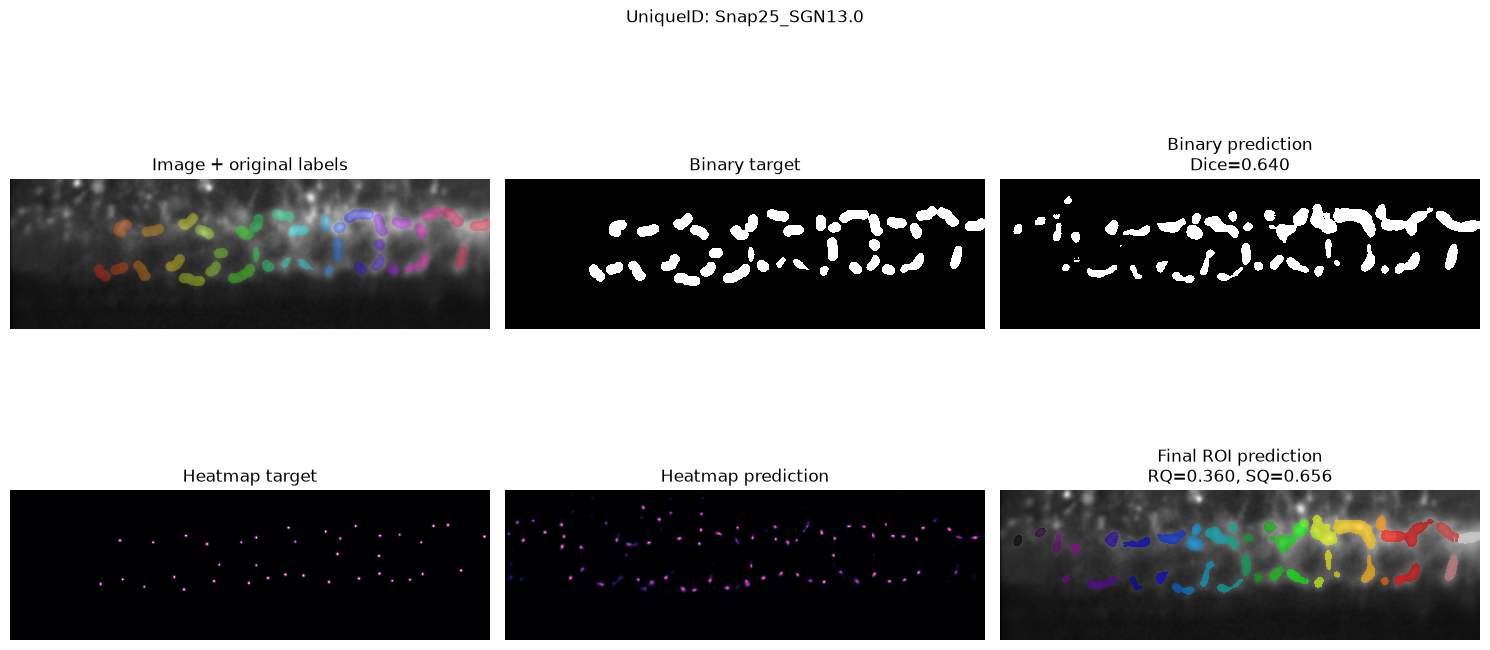

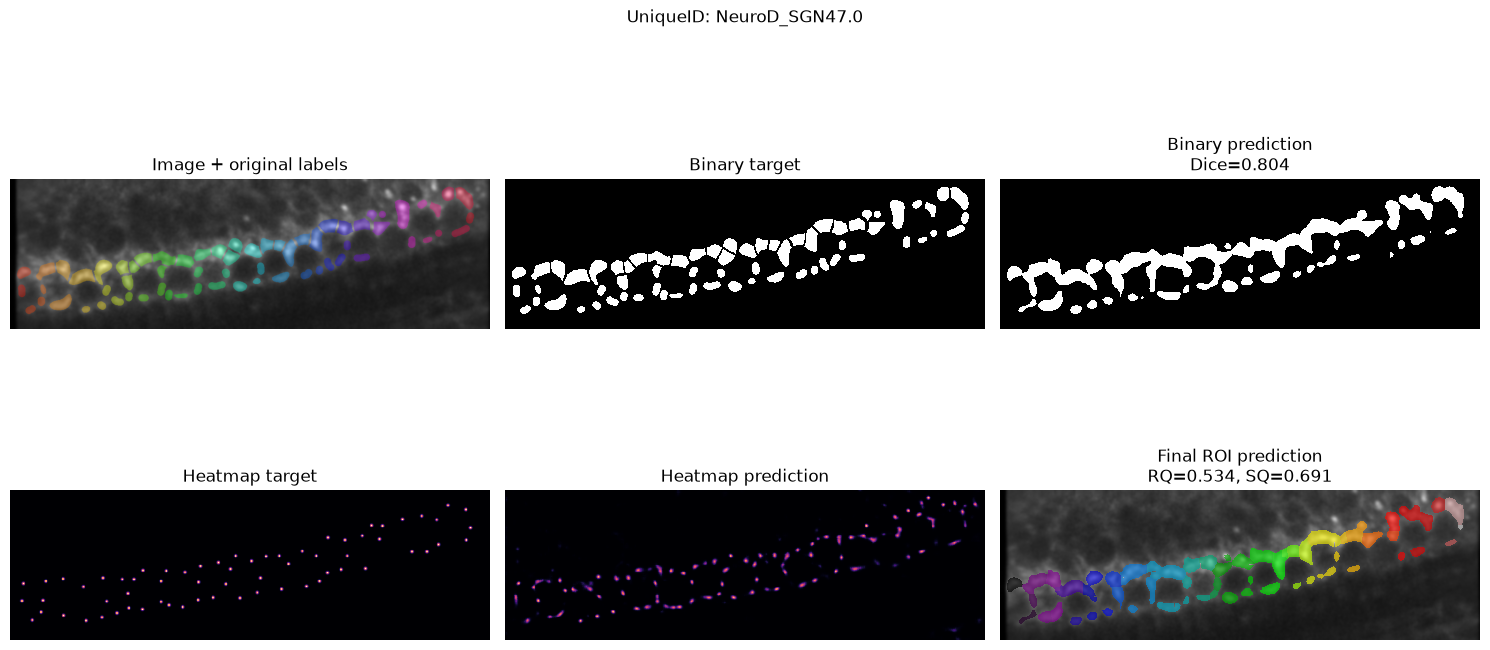

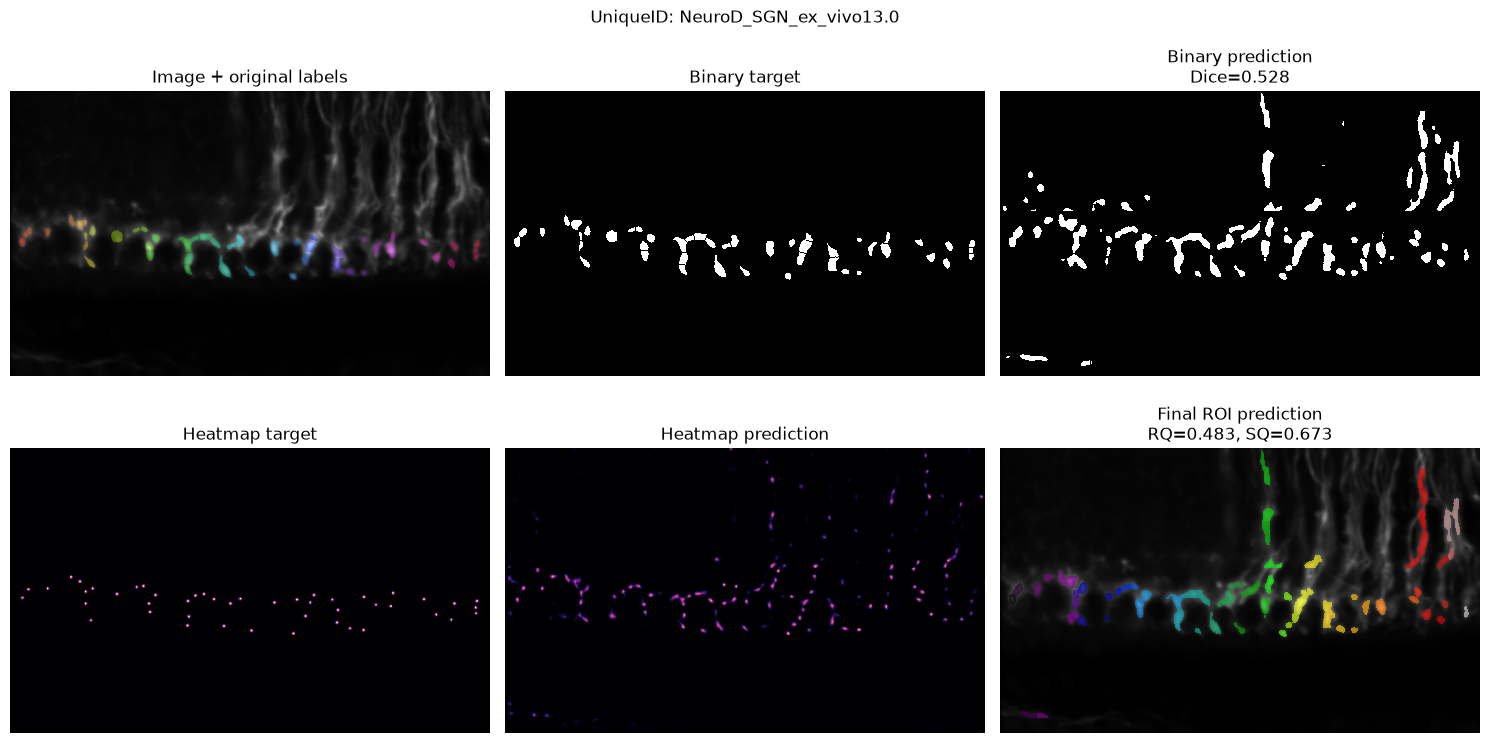

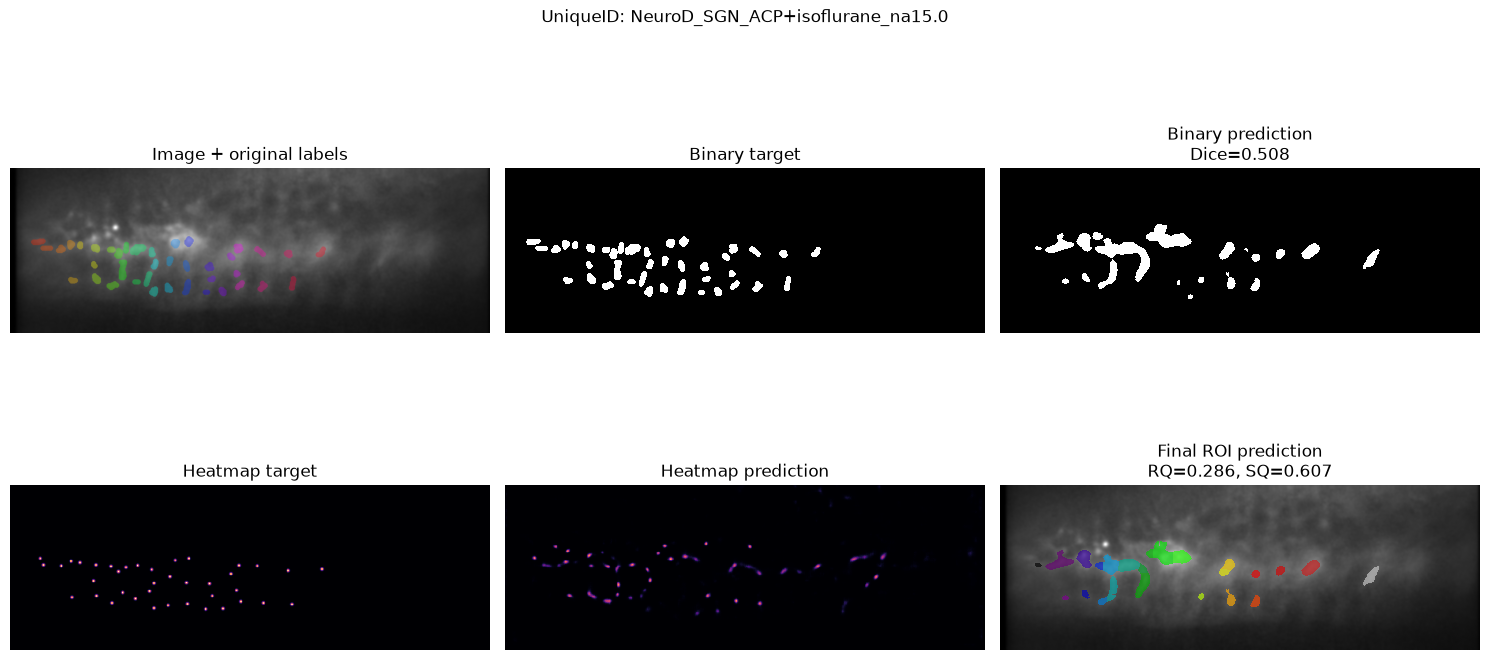

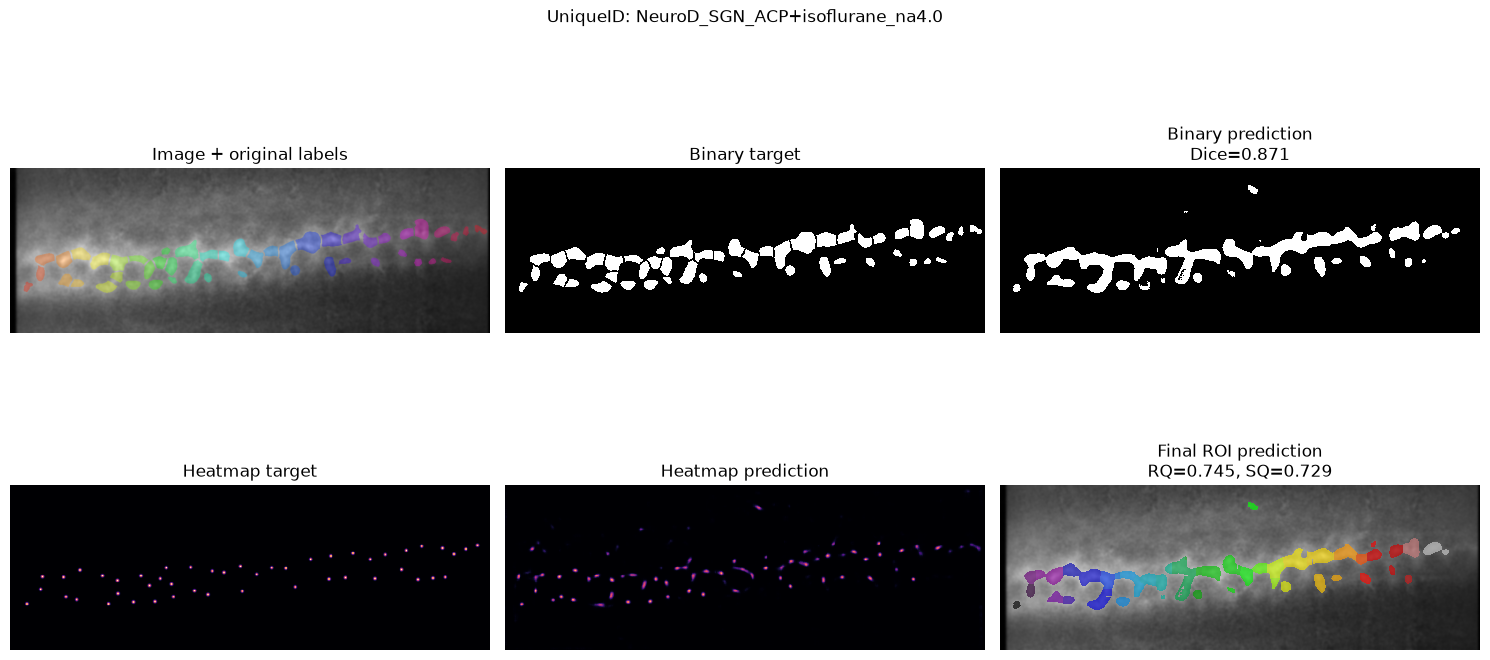

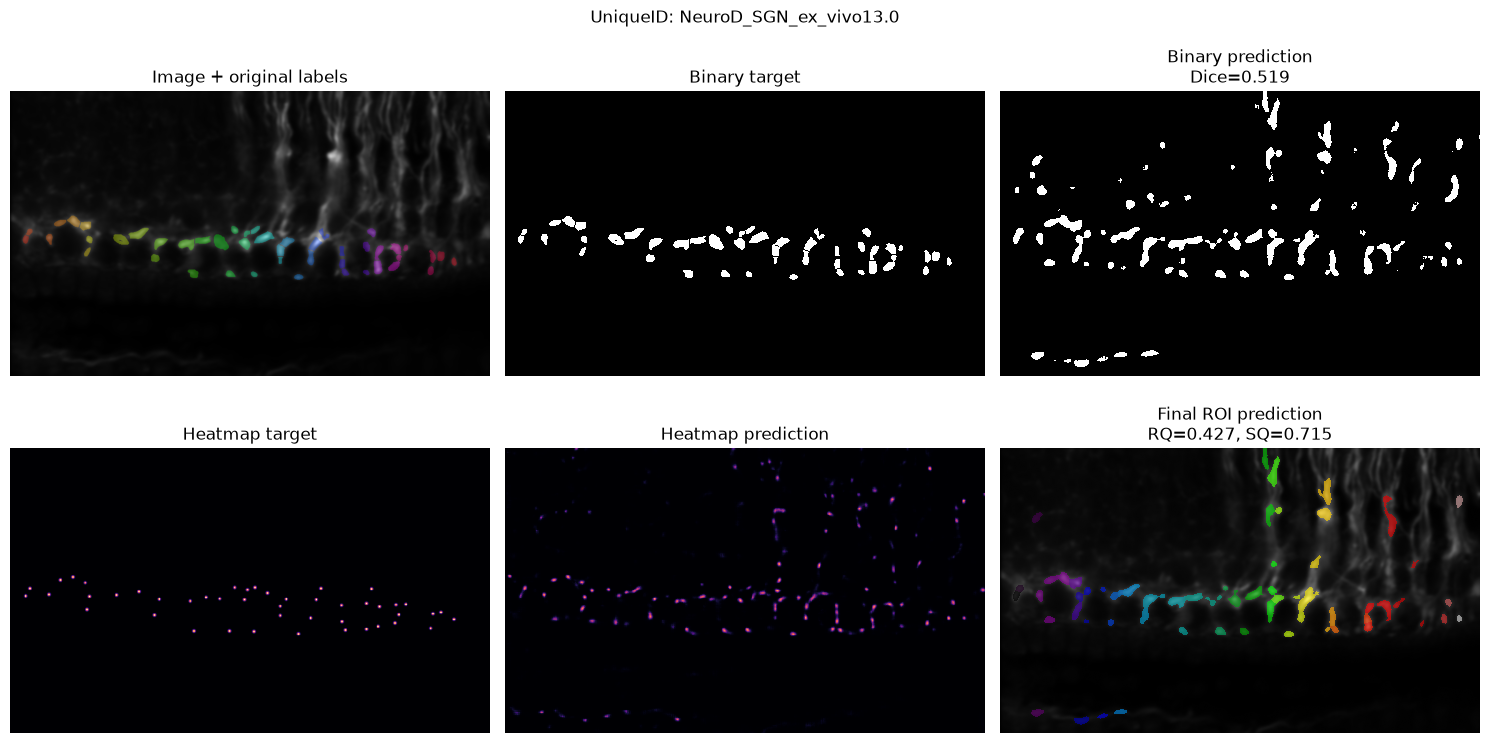

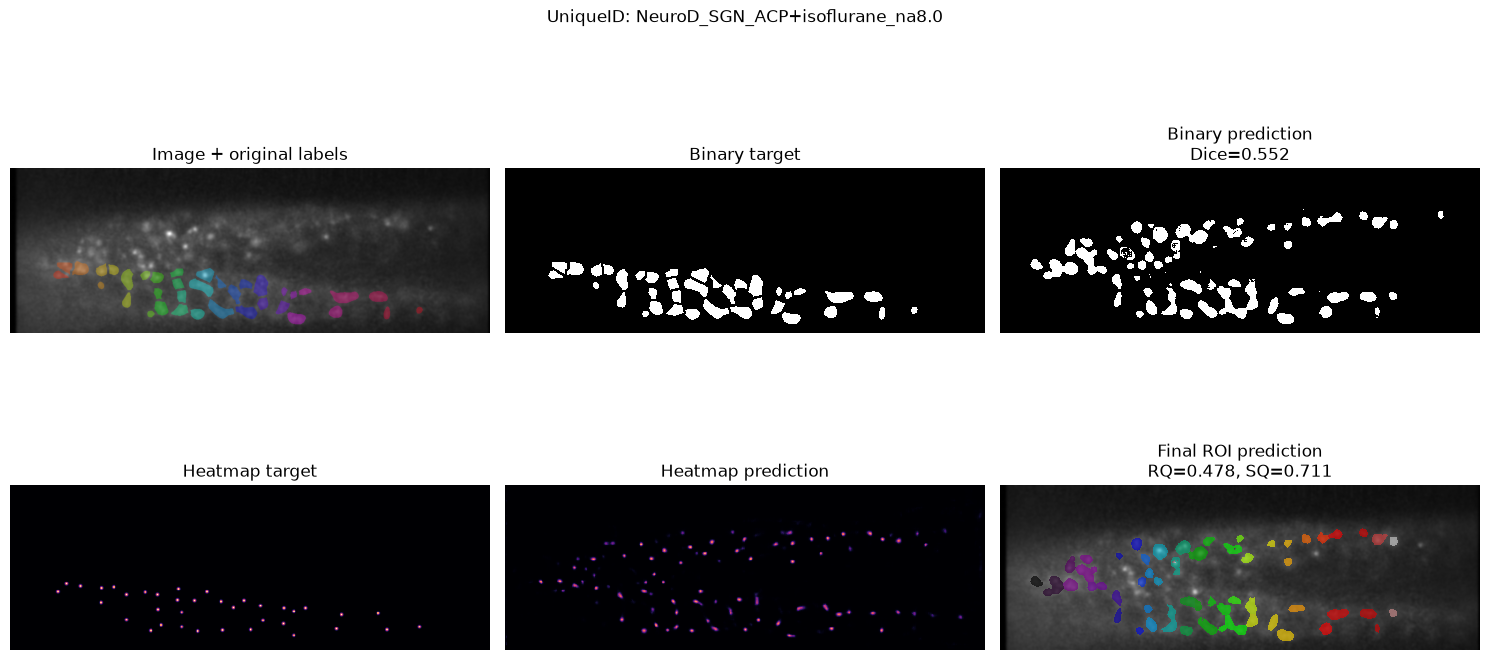

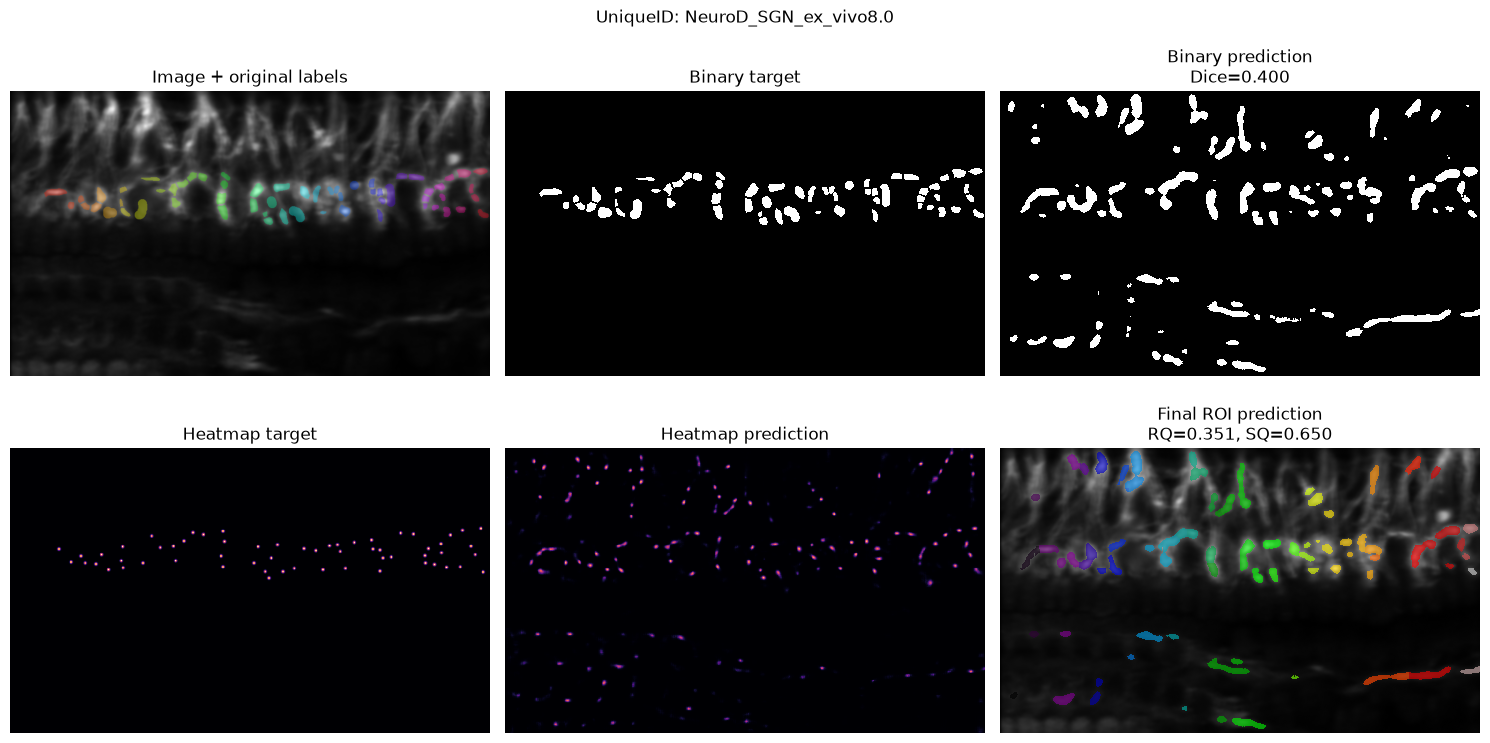

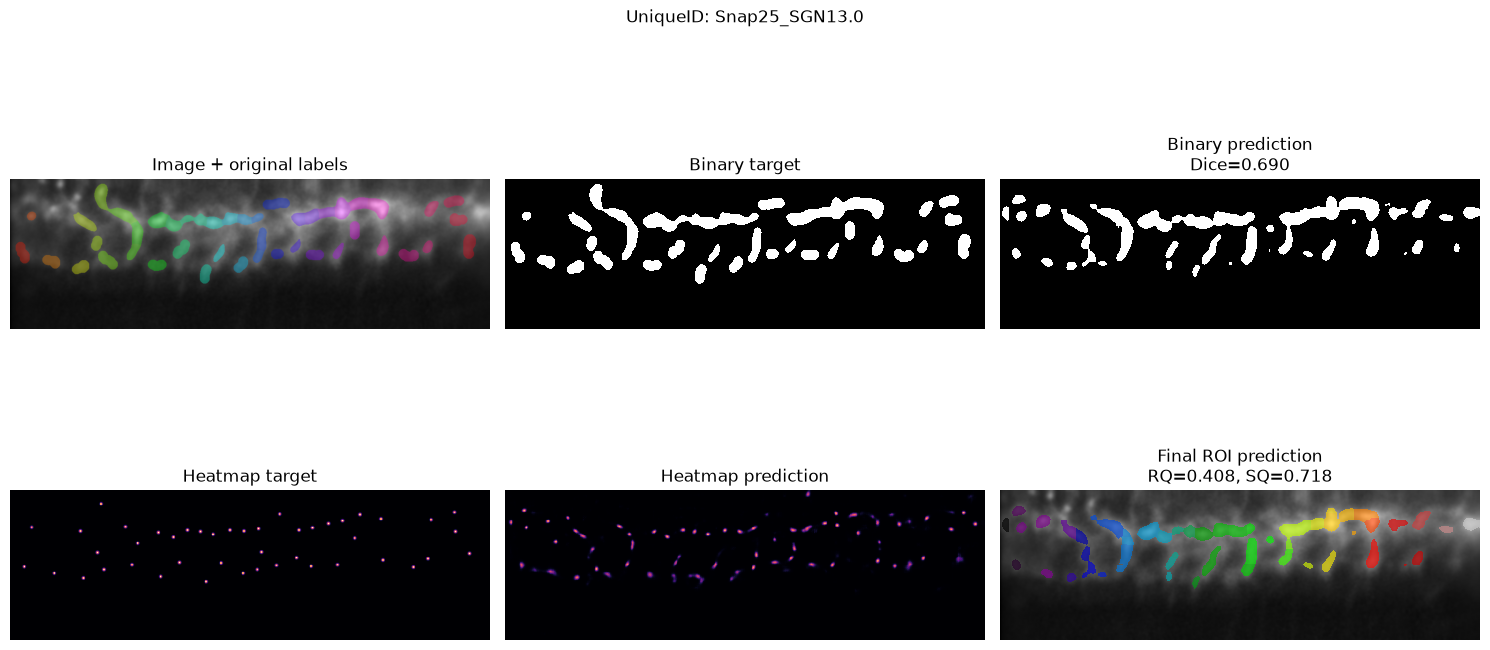

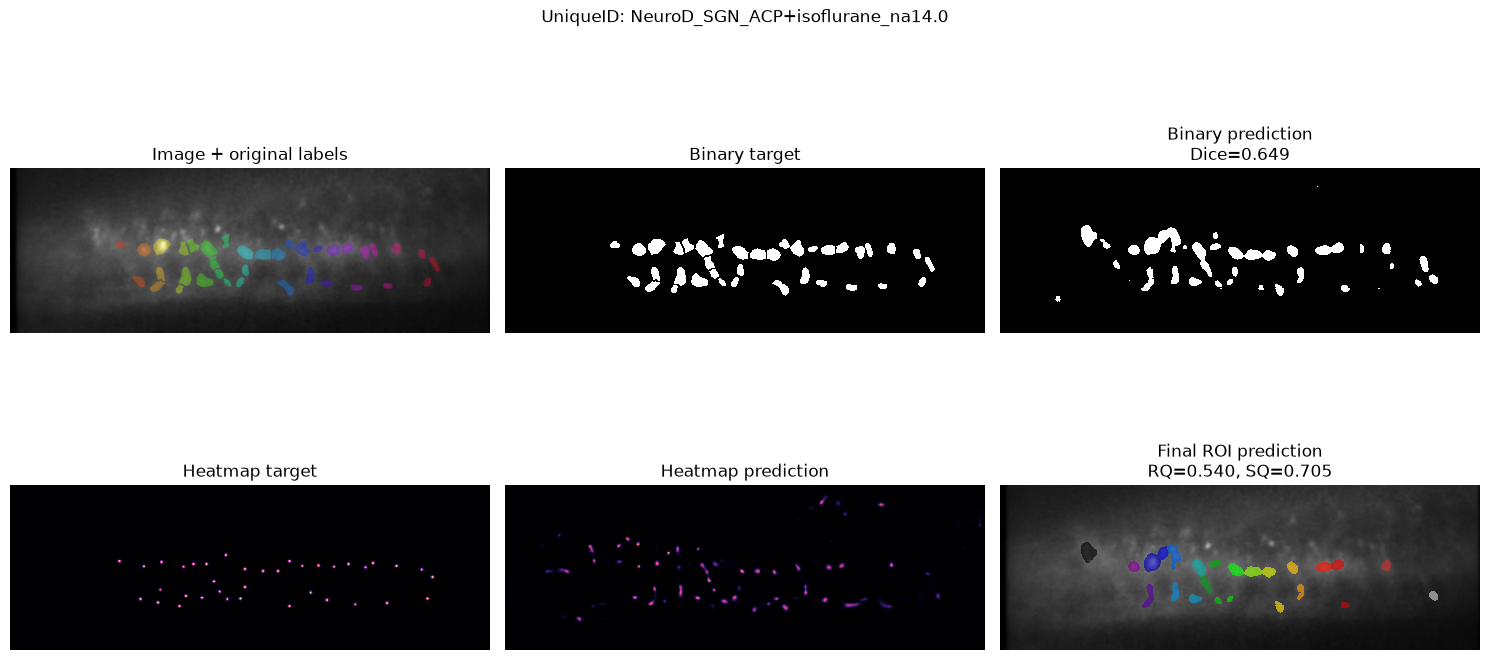

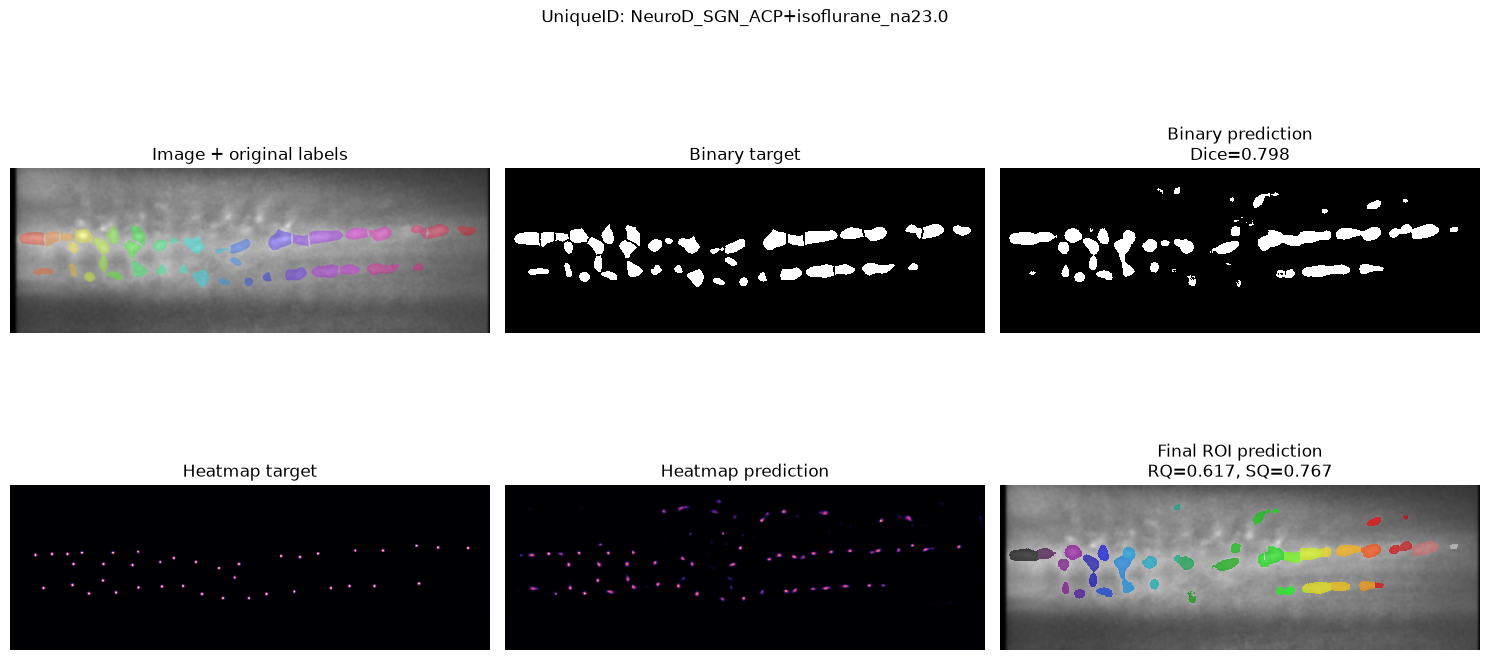

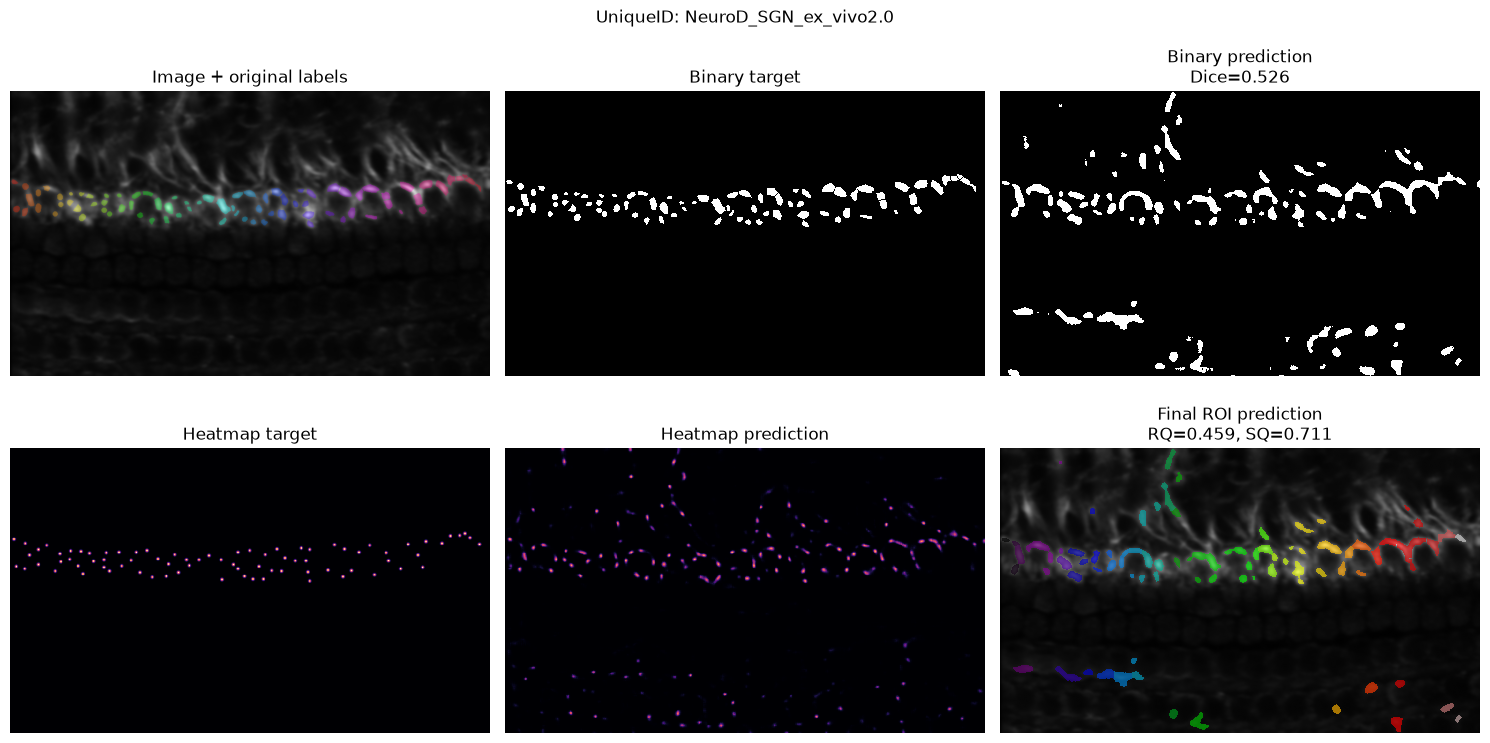

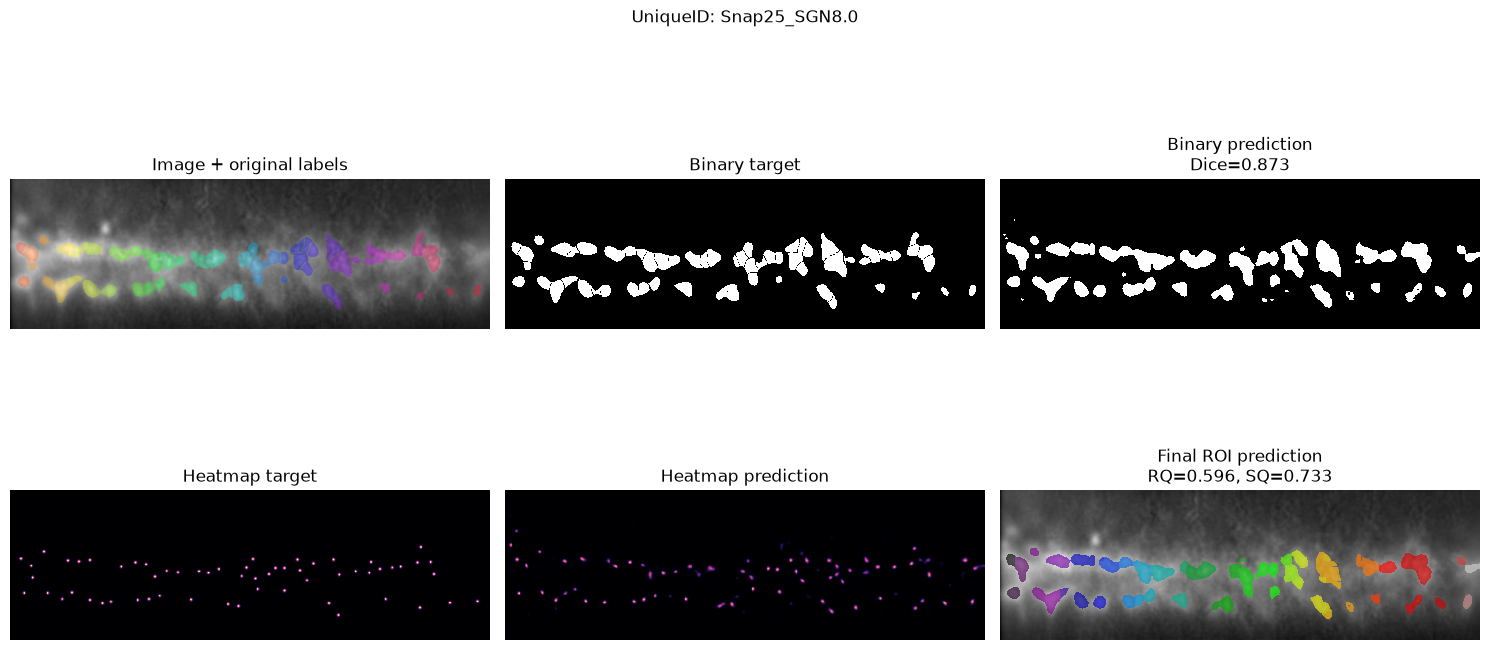

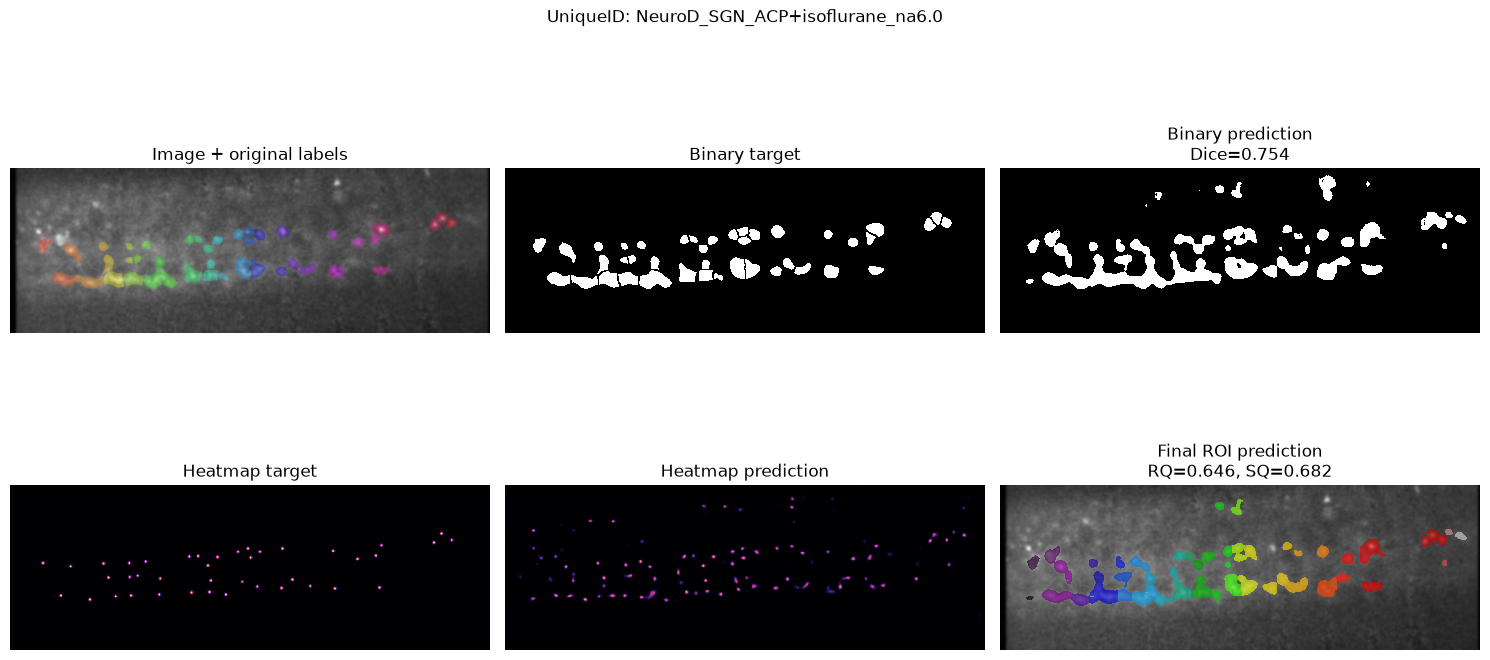

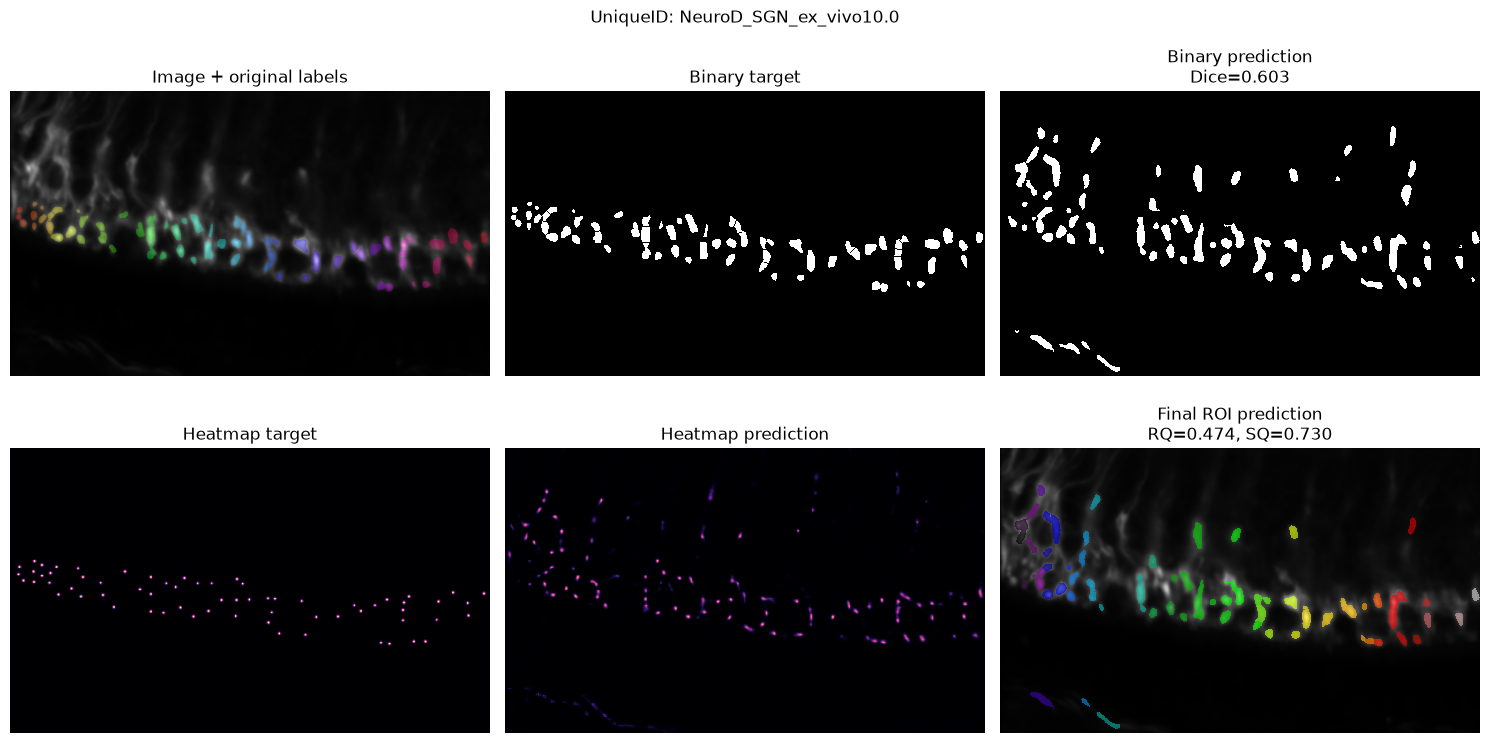

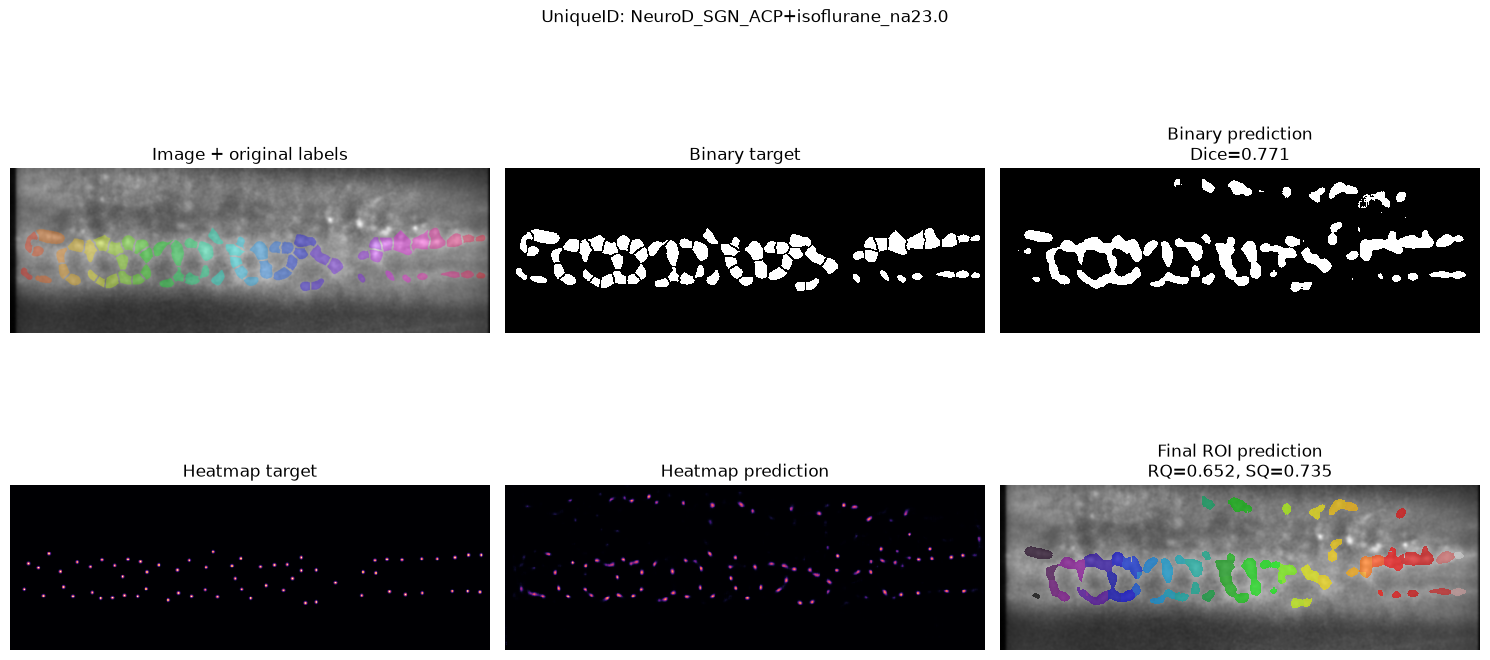

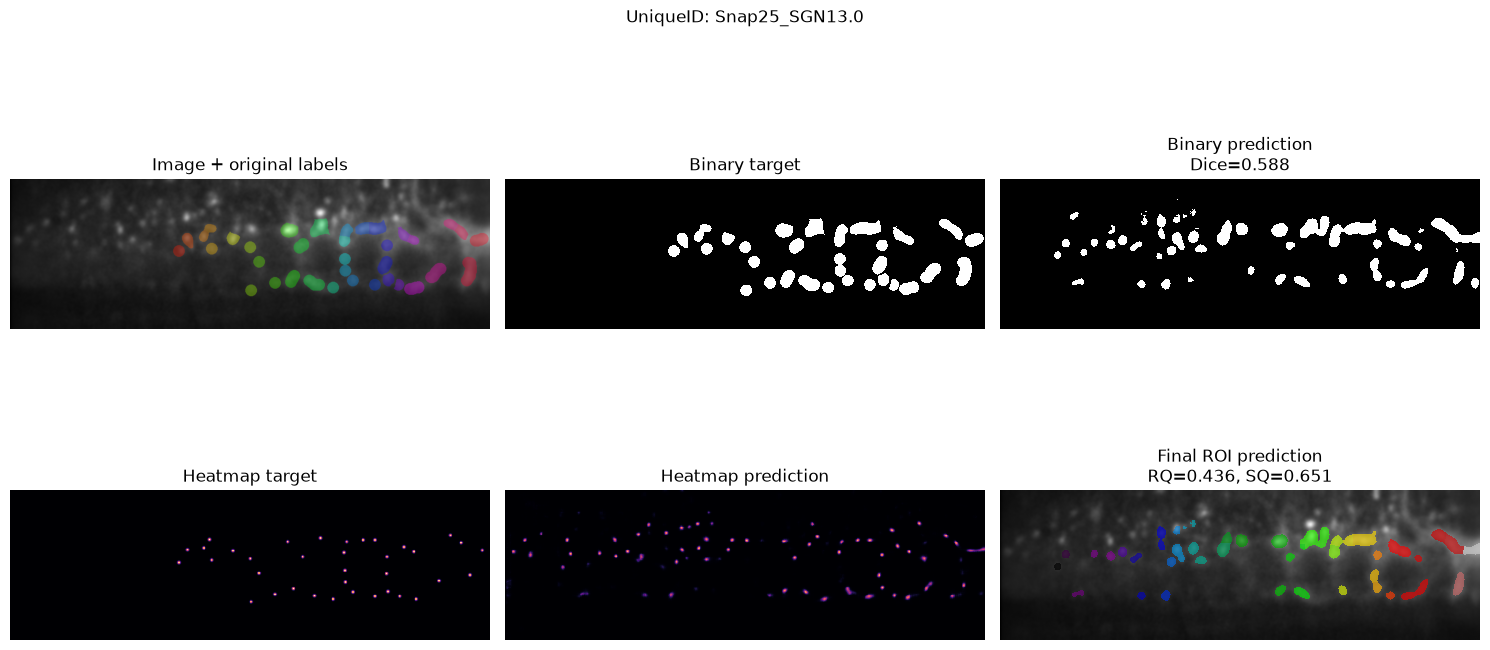

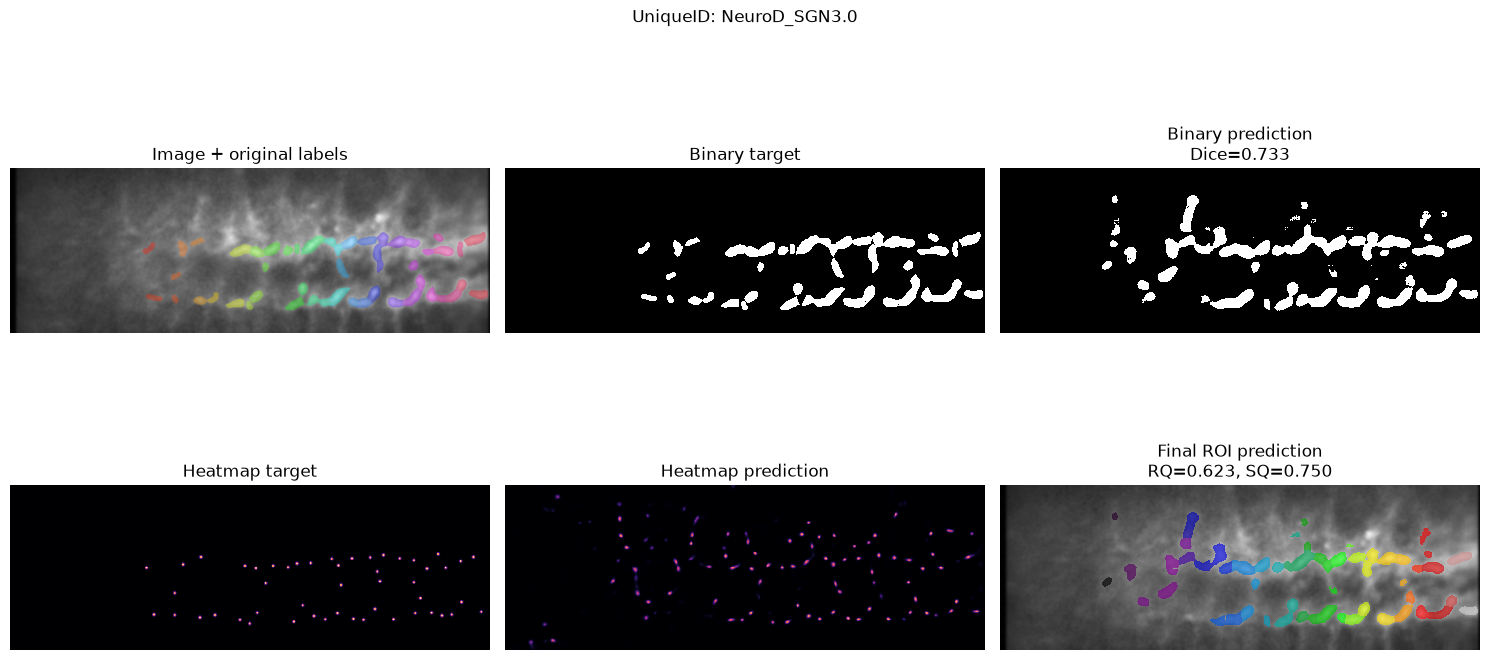

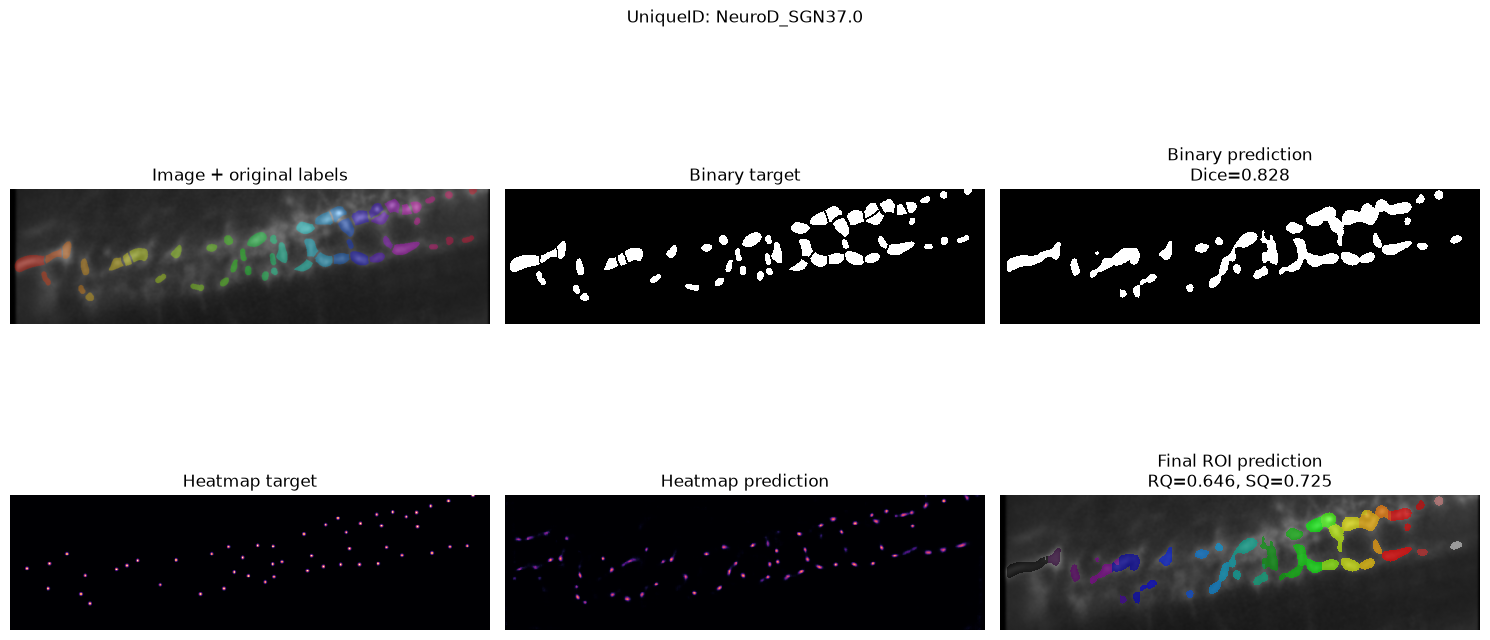

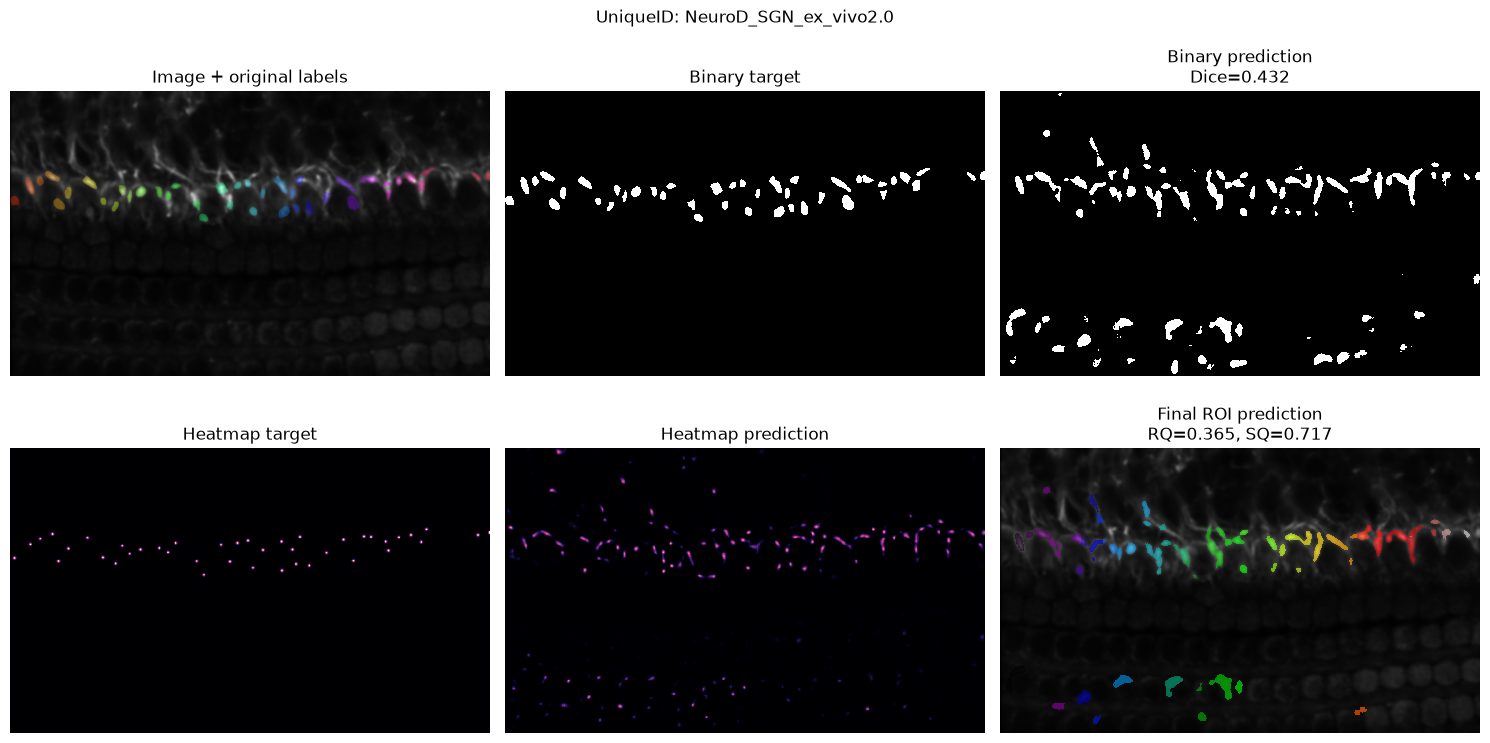

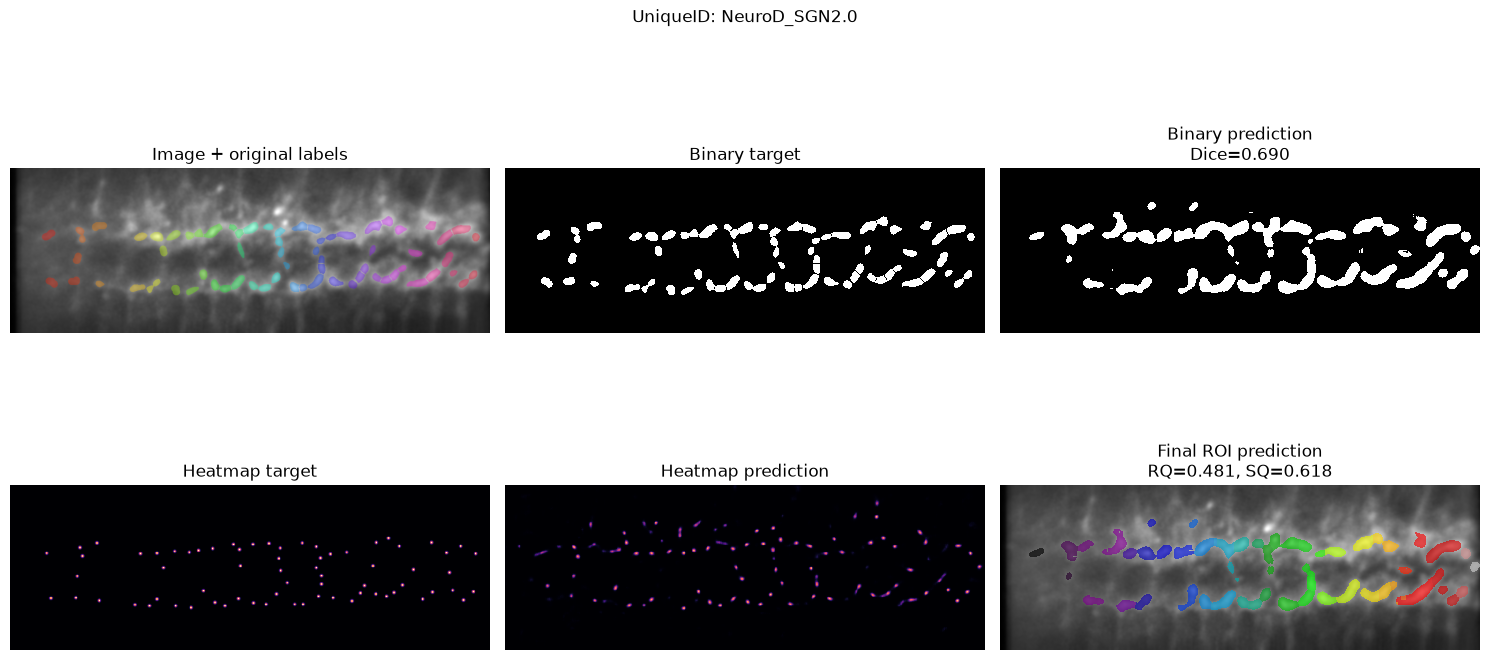

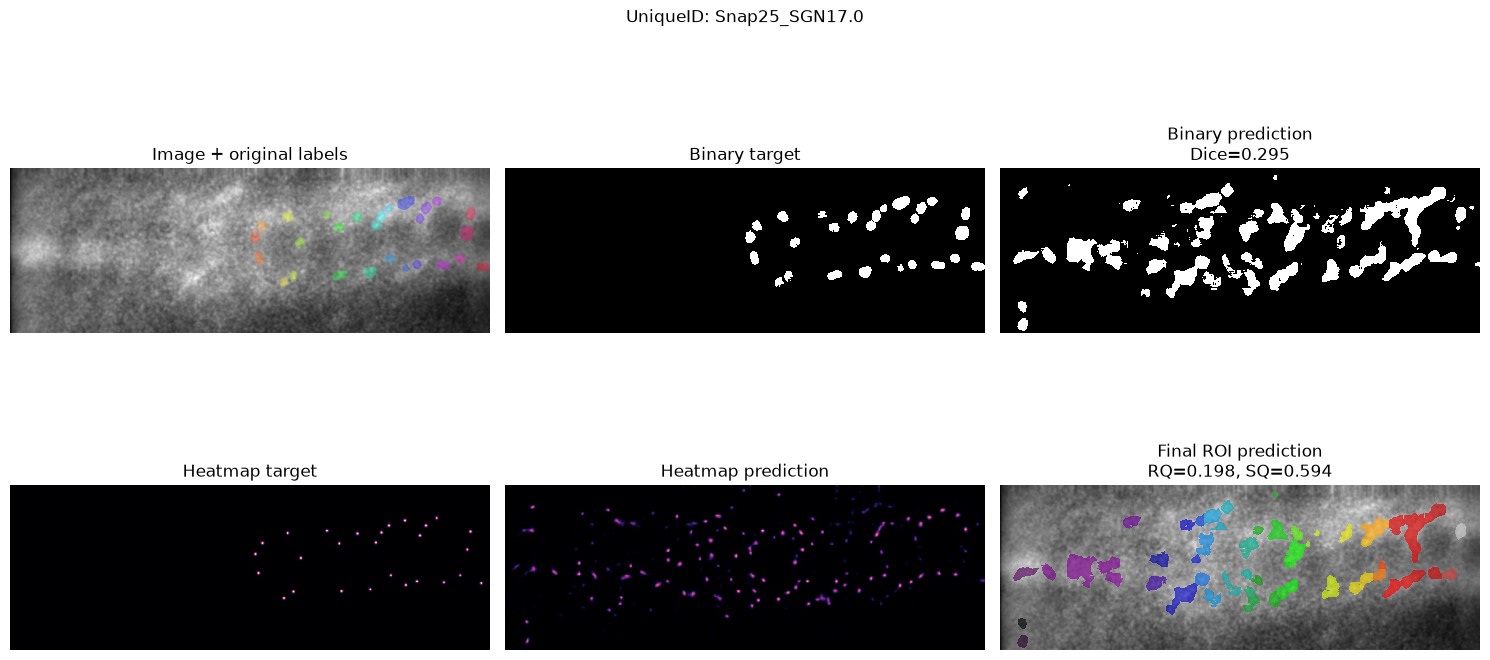

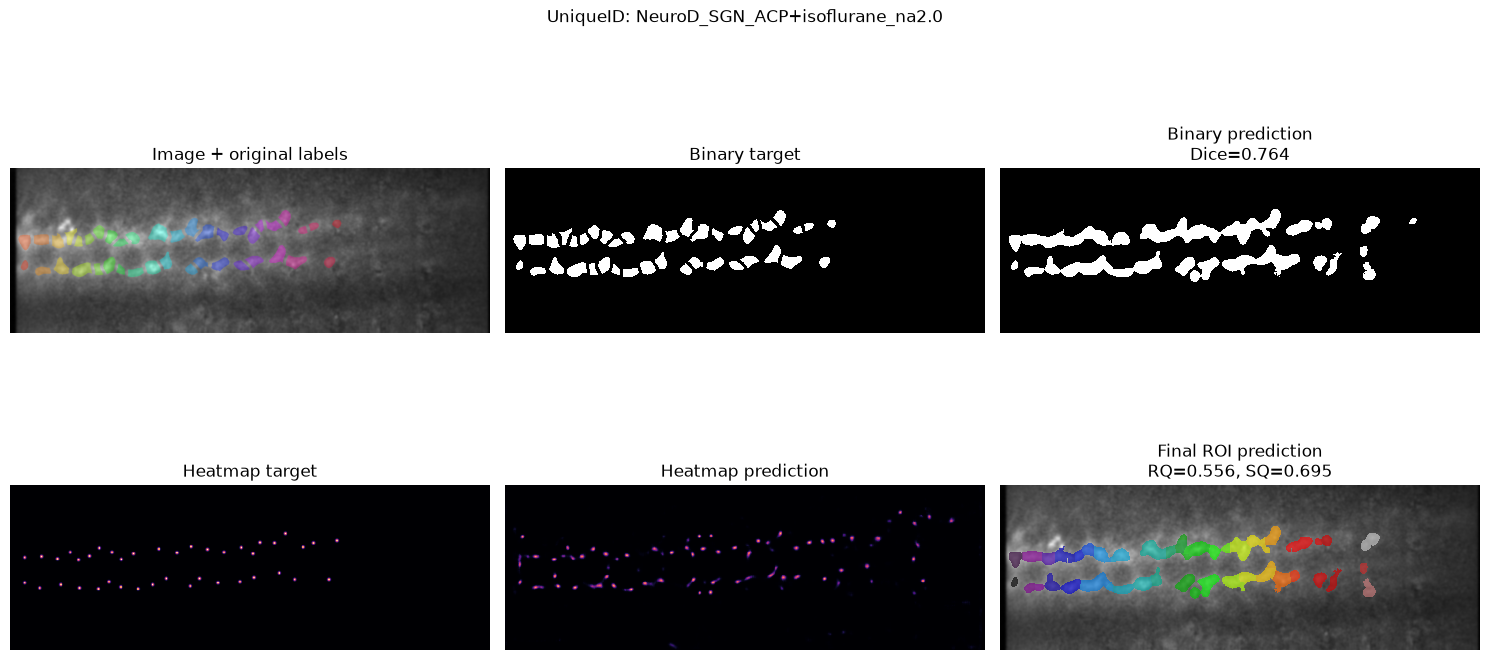

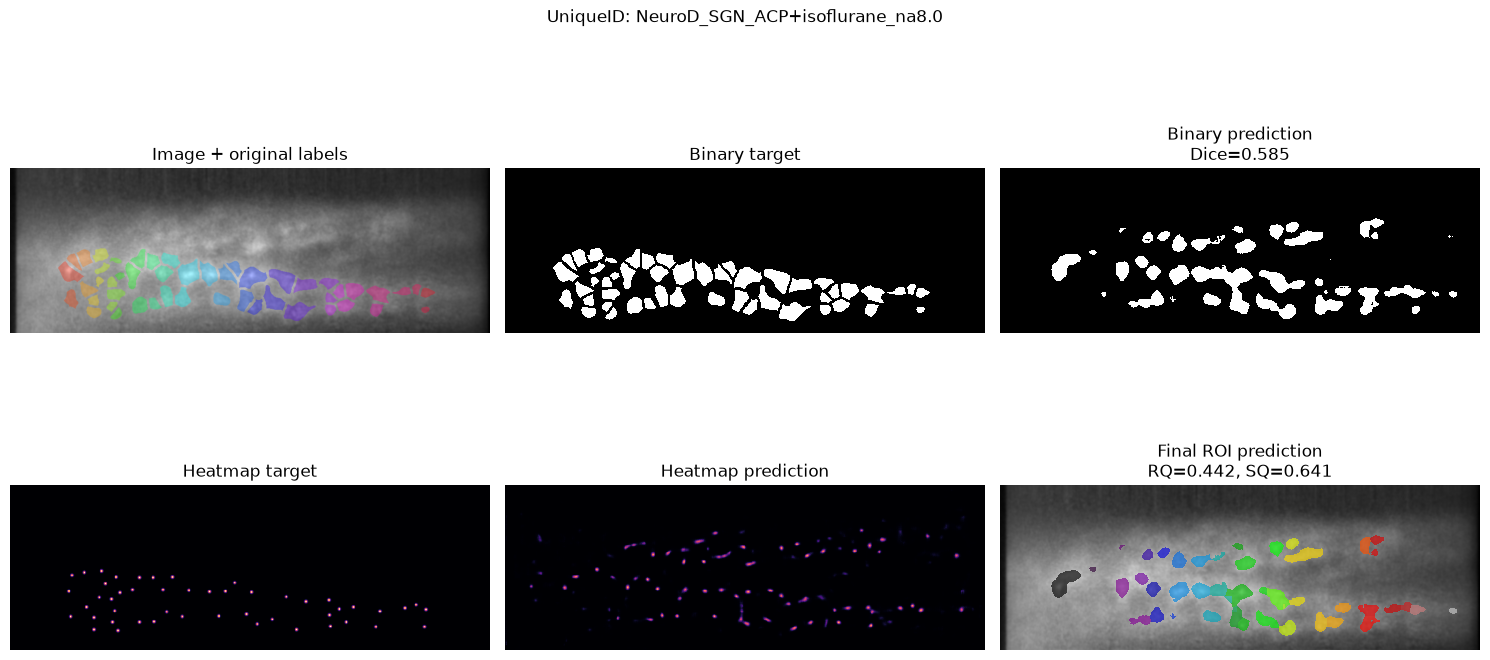

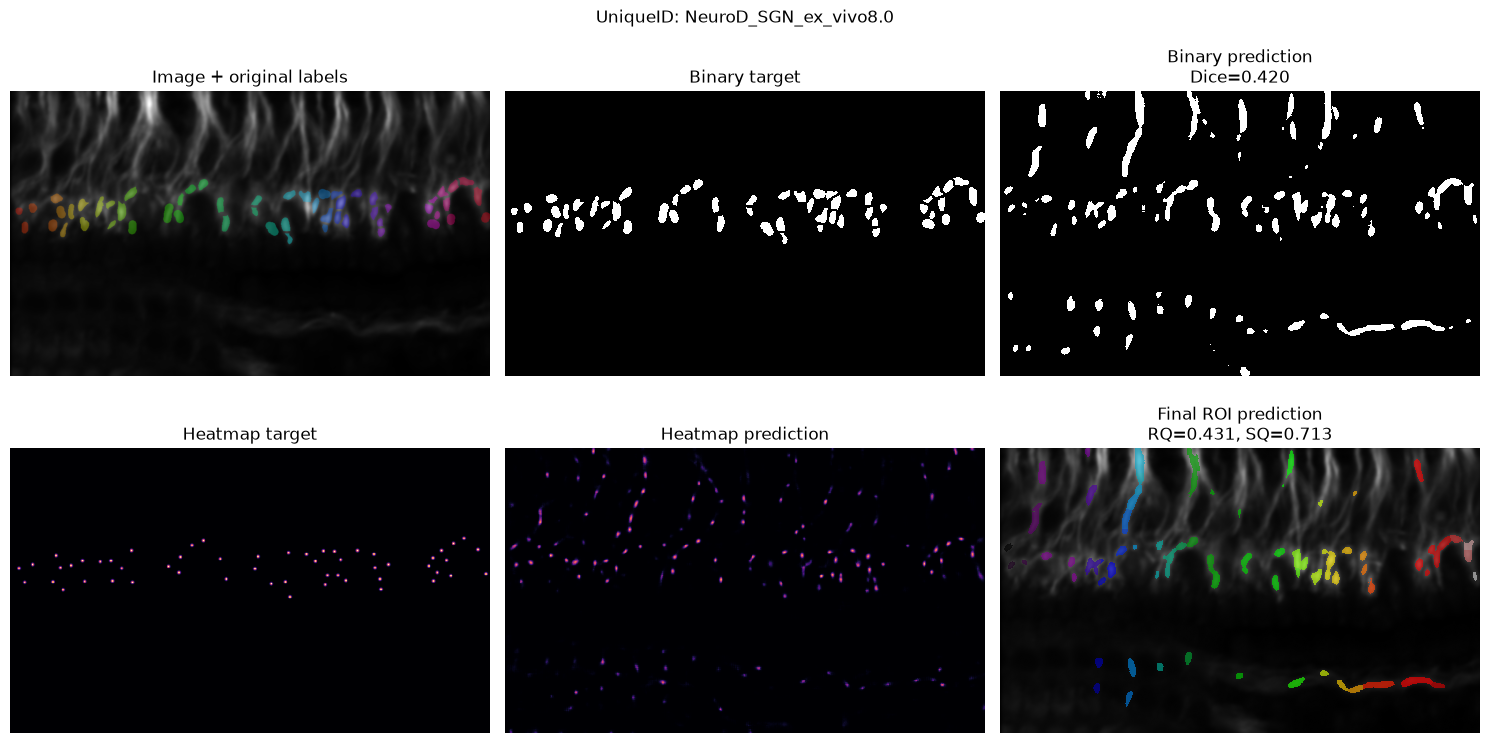

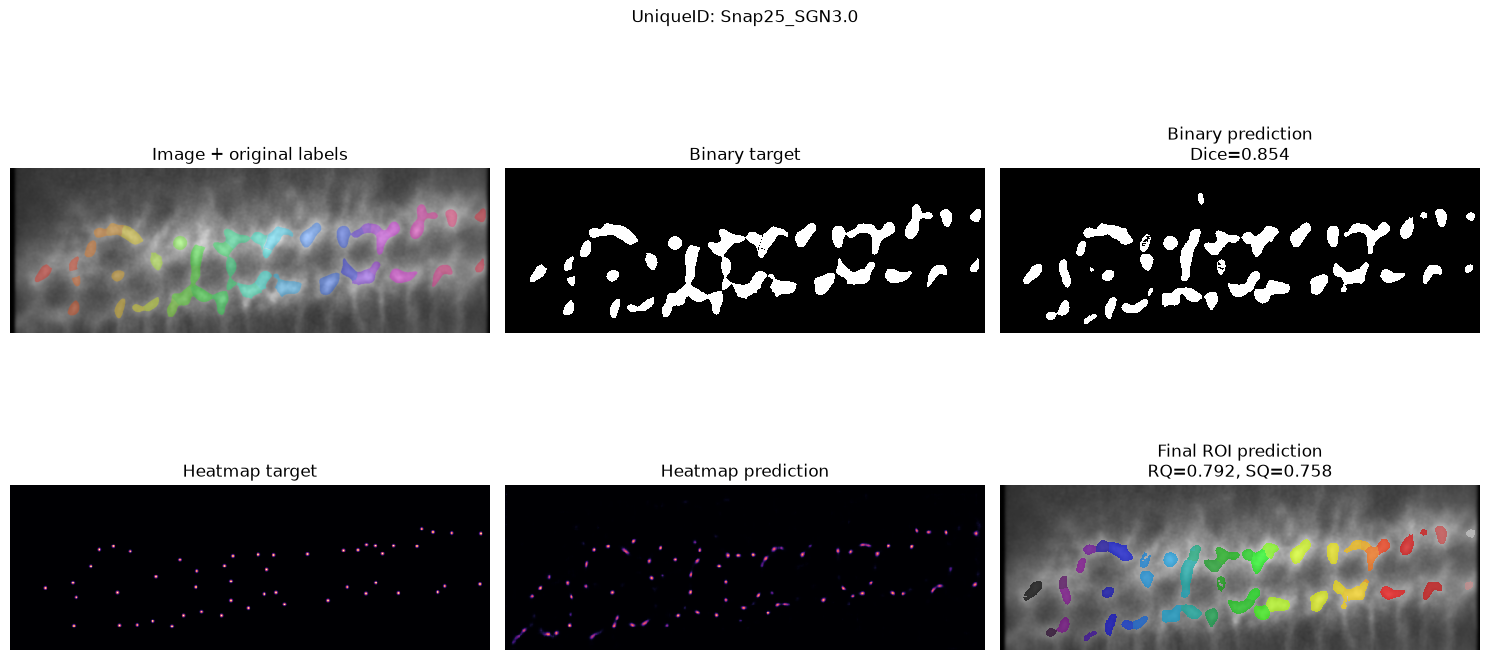

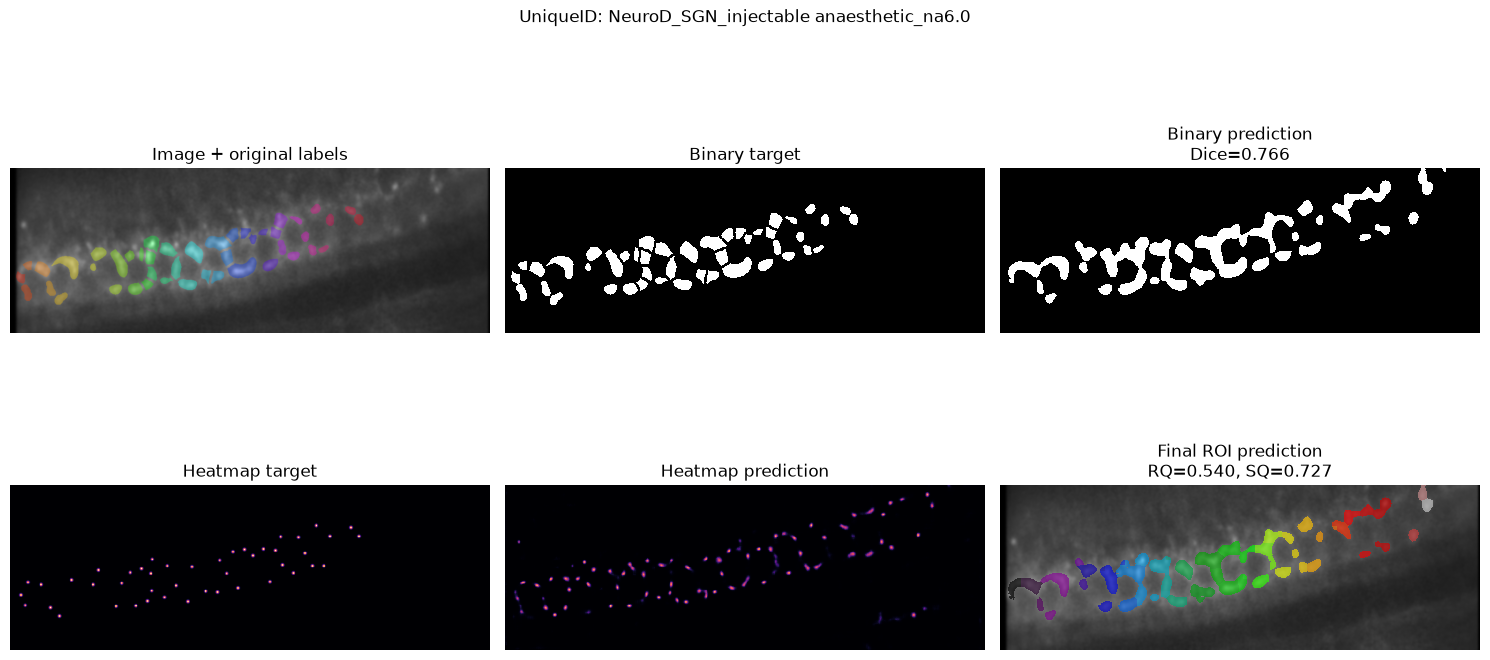

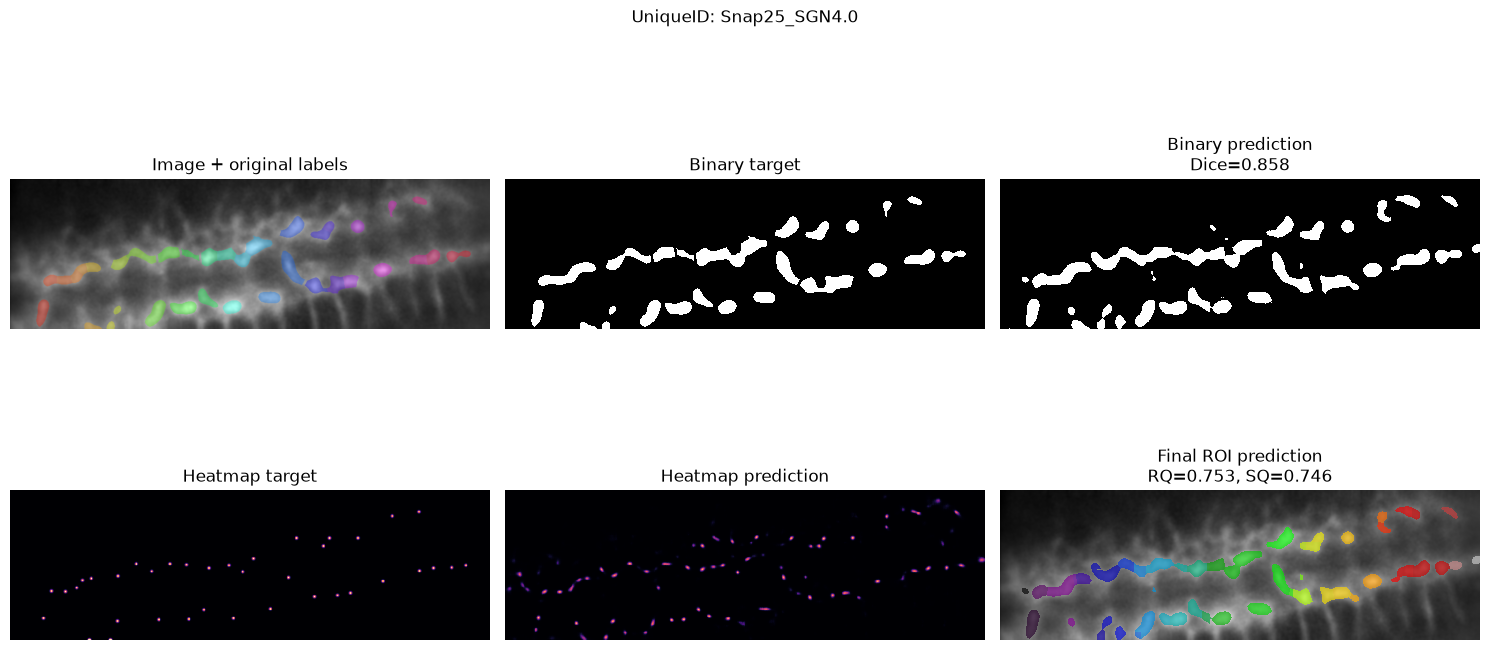

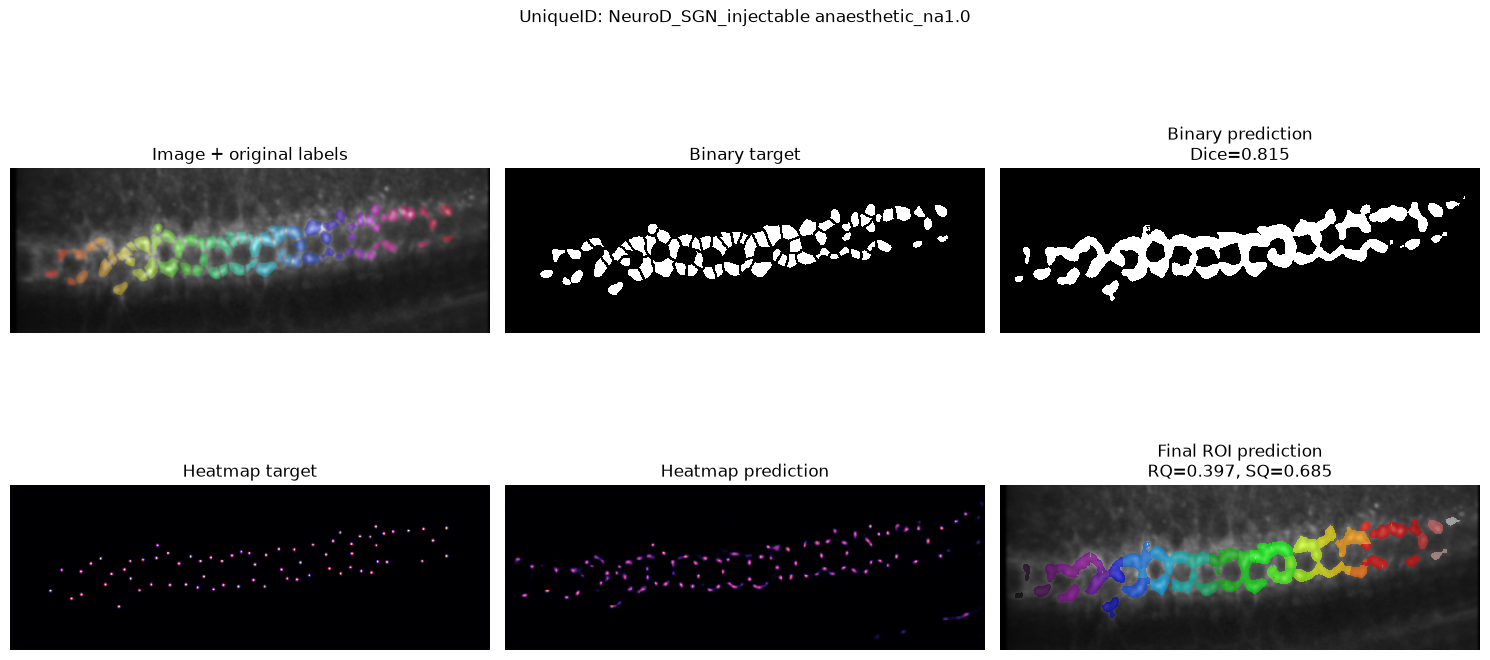

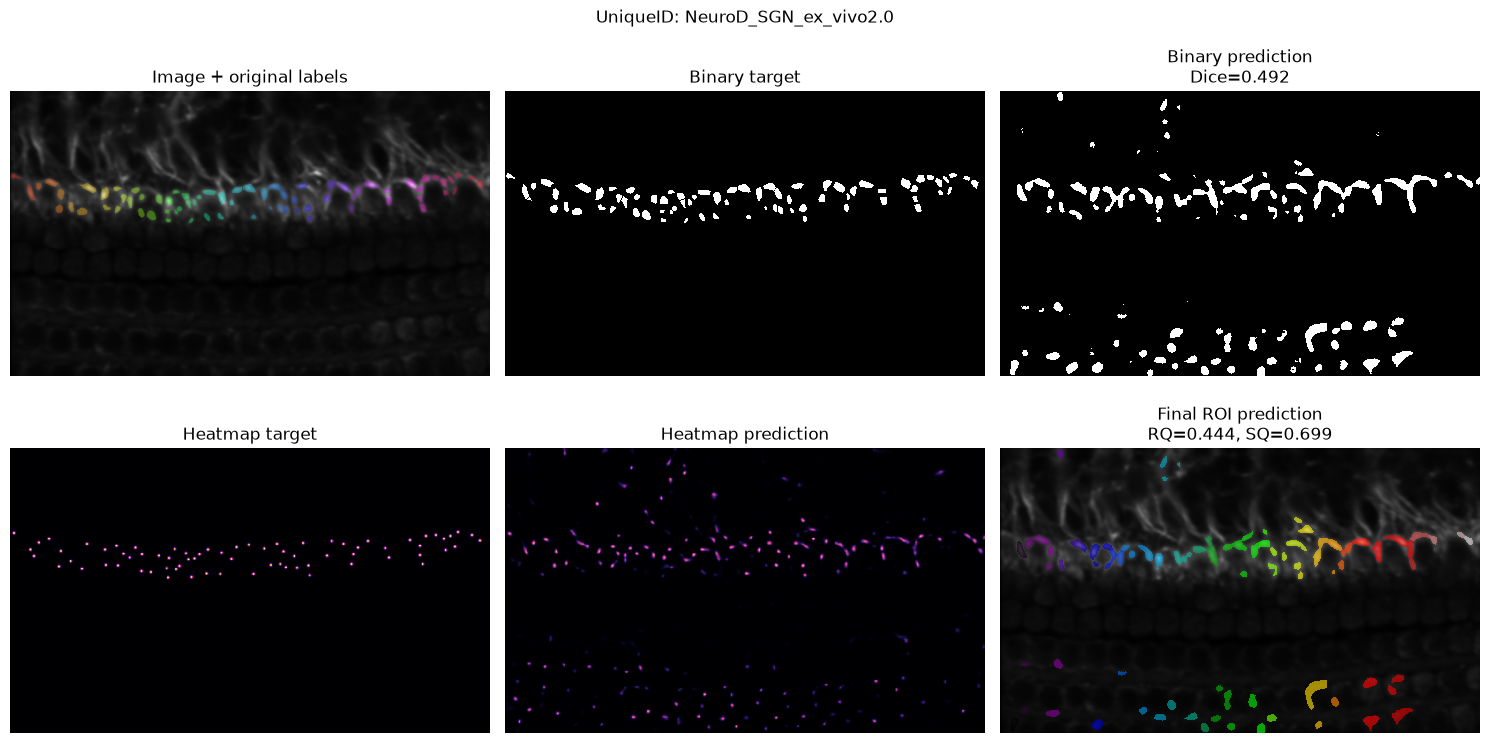

In [5]:
def plot_prediction_grid(sample_index=0, min_distance=5, min_size=20):
    reference_record = binary_run["val_data"][sample_index]
    reference_image_path = reference_record.get("image_path", reference_record["image"])
    uniqueid = reference_record[binary_run["config"]["data"]["column"]]

    binary_idx = find_matching_index(binary_run["val_data"], reference_image_path)
    heatmap_run = next(run for run in model_runs if run["kind"] == "heatmap")
    heatmap_idx = find_matching_index(heatmap_run["val_data"], reference_image_path)

    original = binary_run["original_label_ds"][binary_idx]
    gt_instances = original["label"].cpu()[0].numpy().astype(np.int32)
    overlay = make_overlay(original["image"], original["label"])

    binary_batch = binary_run["val_ds"][binary_idx]
    heatmap_batch = heatmap_run["val_ds"][heatmap_idx]

    binary_image = binary_batch["image"].unsqueeze(0).to(device)
    heatmap_image = heatmap_batch["image"].unsqueeze(0).to(device)
    binary_target = binary_batch["label"].cpu()[0].numpy().astype(np.float32)
    heatmap_target = heatmap_batch["label"].cpu()[0].numpy().astype(np.float32)

    binary_validation_config = binary_run["config"]["validation"]
    heatmap_validation_config = heatmap_run["config"]["validation"]

    with torch.no_grad():
        binary_pred = inference.predict_binary(
            binary_run["model"],
            binary_image,
            device,
            roi_size=tuple(binary_validation_config["roi_size"]),
            sw_batch_size=binary_validation_config["sw_batch_size"],
            prediction_sigmoid=binary_validation_config["prediction_sigmoid"],
            prediction_threshold=binary_validation_config["prediction_threshold"],
        )
        heatmap_pred = inference.predict_heatmap(
            heatmap_run["model"],
            heatmap_image,
            device,
            roi_size=tuple(heatmap_validation_config["roi_size"]),
            sw_batch_size=heatmap_validation_config["sw_batch_size"],
            prediction_sigmoid=heatmap_validation_config["prediction_sigmoid"],
        )

    binary_pred_img = binary_pred.cpu()[0, 0].numpy().astype(np.float32)
    heatmap_pred_img = heatmap_pred.cpu()[0, 0].numpy().astype(np.float32)

    markers = inference.heatmap_to_marker_image(heatmap_pred_img, min_distance=min_distance)
    final_rois = inference.binary_to_instance_labels(
        binary_pred_img,
        min_size=min_size,
        min_distance=min_distance,
        markers=markers,
    )

    binary_dice = dice_score(binary_target, binary_pred_img)
    roi_quality = panoptic_quality_components(gt_instances, final_rois)

    fig, axes = plt.subplots(2, 3, figsize=(15, 8), squeeze=False)

    axes[0, 0].imshow(overlay)
    axes[0, 0].set_title("Image + original labels")

    axes[0, 1].imshow(binary_target, cmap="gray", interpolation="none", vmin=0, vmax=1)
    axes[0, 1].set_title("Binary target")

    axes[0, 2].imshow(binary_pred_img, cmap="gray", interpolation="none", vmin=0, vmax=1)
    axes[0, 2].set_title(f"Binary prediction\nDice={binary_dice:.3f}")

    axes[1, 0].imshow(heatmap_target, cmap="magma", interpolation="none", vmin=0, vmax=1)
    axes[1, 0].set_title("Heatmap target")

    axes[1, 1].imshow(heatmap_pred_img, cmap="magma", interpolation="none", vmin=0, vmax=1)
    axes[1, 1].set_title("Heatmap prediction")

    roi_display = np.ma.masked_where(final_rois == 0, final_rois)
    axes[1, 2].imshow(binary_image.cpu()[0, 0].numpy(), cmap="gray")
    axes[1, 2].imshow(roi_display, cmap="nipy_spectral", interpolation="none", alpha=0.65)
    axes[1, 2].set_title(f"Final ROI prediction\nRQ={roi_quality['rq']:.3f}, SQ={roi_quality['sq']:.3f}")

    for ax in axes.flat:
        ax.axis("off")

    fig.suptitle(f"UniqueID: {uniqueid}")
    fig.tight_layout()
    plt.show()


for sample_index in range(min(30, len(binary_run["val_data"]))):
    plot_prediction_grid(sample_index=sample_index)
